# Лабораторная работа №4. Акустическая модель (FastSpeech 2)

**Курс «Синтез речи», Университет ИТМО**

Обучение акустической модели FastSpeech 2 (coqui-TTS, `ForwardTTS`) на фонемной разметке корпуса RUSLAN из работ №1–3 и оценка результата: синтез 120 отложенных фраз через Гриффина–Лима, MCD, диапазон мела, длительности и интонация.

**Критерии приёмки (из README):**

| Критерий | Порог |
|---|---|
| Обучена хотя бы одна модель, и она **говорит** | обязательно |
| Все 120 отложенных предложений синтезированы | обязательно |
| MCD модели ниже MCD постоянного мела | обязательно |
| Диапазон мела сопоставим с настоящим | обязательно |

**Кратко о результатах:**

- Основная модель `gt` (GT-фонемы, 84 тыс. шагов ≈ 80 эпох, лучший по eval чекпоинт - 73,85 тыс.) **говорит**: CER распознавания Whisper 2,3 % при 2,0 % у copysynth (настоящий мел через тот же Гриффин–Лим) и 1,7 % у записи. MCD 28,65 дБ против 62,13 у постоянного мела, диапазон мела в пределах допуска - все критерии приёмки выполнены.
- Слабое место базовой модели - **нет гармоник и, как следствие, нет тона**: pYIN не находит F0 в её синтезе. Это исправляют предсказатели высоты тона и энергии (доп. задание 2).
- Выданная схема обучения за разумное время ничему не учится (расписание lr шагает раз в эпоху), а запуск на 8 ГБ шёл в 10–30 раз медленнее возможного; исправления - в разделе 3.1. В coqui найдена ошибка `collate_fn`, которая ломает обучение на внешних длительностях (раздел 7).
- Обучение на фонемах G2P после выхода с плато догоняет `gt` (раздел 6.1); ошибки G2P при синтезе на разборчивость почти не влияют.
- Доп. задания: длительности MFA - плато нет вовсе, лучшая разборчивость на 30 тыс. шагов (CER 2,0 %); предсказатели F0/энергии - гармоники и интонация (сглаженная) появляются.

**Состав работы:**

| файл | что делает |
|---|---|
| `prepare_data.py` | метаданные v3 из лабы 3 → `data/metadata_phones*.csv`, разбиение train/test по `id % 5`, eval-набор с фонемами нашего G2P |
| `train_fastspeech2.py` | выданный скрипт обучения + флаги: `--lr-schedule`, `--precision`, `--shuffle`, `--gpu-mem-fraction`, `--init-from`, `--cache-dir`, ограничение потоков BLAS |
| `prepare_mfa_durations.py` | (выдан) длительности из TextGrid MFA для доп. задания 1 |
| `precompute_pitch_energy.py` | кэш F0/энергии для доп. задания 2 заранее, на CPU, параллельно с другим обучением |
| `evaluate.py` | (выдан) синтез 120 фраз и MCD + флаги `--out-name`, `--save-mels` (мелы и длительности для анализа) |
| `analysis.py` | кривые из TensorBoard, F0 (pYIN) и сравнение контуров по DTW |
| `asr_eval.py` | разборчивость: Whisper → CER/WER |
| `run_queue.sh` | очередь запусков на GPU (переживает закрытие терминала) |
| `eval_queue.sh` | очередь оценок на CPU: ждёт нужный чекпоинт и запускает `evaluate.py`, пока GPU занят обучением |

In [ ]:
import json, os, re, glob, time, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display, Markdown

import analysis as A
from evaluate import dtw_align, mel_to_mfcc, mcd
# coqui при импорте TTS.tts.utils.visual делает matplotlib.use("Agg") - после него возвращаем графики в ноутбук
import TTS.tts.utils.visual  # noqa: F401
%matplotlib inline

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path("../..")
DATA = ROOT / "data"
RUNS = Path("runs")
WAVS = DATA / "RUSLAN" / "RUSLAN"
STEPS_PER_EPOCH = 1054          # batch 16 (see section 3)

def read_meta(path):
    return pd.read_csv(path, sep="|", header=None, names=["id", "text", "phones"],
                       quoting=3, dtype=str, keep_default_na=False)

def run_dir(name):
    """runs/<name>/<name>-<date>-<hash>/ (coqui adds a dated subdirectory)."""
    found = sorted((RUNS / name).glob(f"{name}-*"))
    return found[-1] if found else None

def run_config(name):
    d = run_dir(name)
    return json.loads((d / "config.json").read_text(encoding="utf-8")) if d else None

D:\python_projects\ITMO\tts_labs_itmo\data\venv_tts\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Окружение

Отдельное окружение `data/venv_tts` (Python 3.13, в `.gitignore`), чтобы не ломать окружение работ 1–3:

- `torch 2.7.1+cu126` - README проверялся на 3.11 / torch 2.5.1, форк coqui поддерживает Python 3.10–3.14;
- форк coqui-TTS установлен в режиме редактирования из клона `data/coqui-ai-TTS` (ветка `tts-course-itmo-2026-m1`), чтобы читать и при необходимости править исходники.

Проблемы при установке и их решения:

| проблема | решение |
|---|---|
| `pip install "TTS @ git+…"` из README падает: *inconsistent name: expected 'tts', but metadata has 'coqui-tts'* (новый pip проверяет имя пакета) | ставить как `coqui-tts @ git+…` или из клона: `pip install -e ./coqui-ai-TTS` |
| `ImportError: cannot import name 'isin_mps_friendly'` - подтянулся `transformers 5.x` | `pip install "transformers>=4.57,<5"` (об этом предупреждает README) |
| `ModuleNotFoundError: six` | `pip install six` - зависимость не указана в `pyproject.toml` форка |

**Результат этапа:** импорт `torch` и `TTS` работает, CUDA доступна.

In [2]:
import torch, TTS, trainer, librosa, transformers
print(f"python      {os.sys.version.split()[0]}")
print(f"torch       {torch.__version__}, CUDA {torch.version.cuda}, cuda available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU         {p.name}, {p.total_memory / 2**30:.1f} GiB, compute capability {p.major}.{p.minor}")
print(f"coqui-tts   {TTS.__version__} (fork Arbaletos/coqui-ai-TTS@tts-course-itmo-2026-m1, editable)")
print(f"trainer     {trainer.__version__}")
print(f"librosa     {librosa.__version__}, transformers {transformers.__version__}")

python      3.13.6
torch       2.7.1+cu126, CUDA 12.6, cuda available: True
GPU         NVIDIA GeForce RTX 3070 Ti, 8.0 GiB, compute capability 8.6
coqui-tts   0.27.5 (fork Arbaletos/coqui-ai-TTS@tts-course-itmo-2026-m1, editable)
trainer     0.3.3
librosa     1.0.0, transformers 4.57.6


## 2. Подготовка данных

### 2.1. Аудио: 44,1 → 22,05 кГц

Корпус был скачан в исходной частоте 44 100 Гц (в лабах 1–3 это было не важно). Пересэмплирование выполнено локально: `ffmpeg -af aresample=resampler=soxr:precision=28 -ar 22050`, 14 параллельных процессов, ~6,5 мин на 22 200 файлов. Исходники сохранены в `data/RUSLAN/RUSLAN_44100`, рабочие файлы - в `data/RUSLAN/RUSLAN` (путь по умолчанию у всех скриптов).

**coqui не проверяет частоту файла** (`load_wav` читает `soundfile` при `resample=False` и частоту отбрасывает). На 44,1 кГц обучение молча шло бы на растянутом вдвое звуке: кадр 256 отсчётов длился бы 5,8 мс вместо 11,6, а мел-полосы соответствовали бы вдвое более низким частотам - и вокодер лабы 5 такой мел бы не понял.

In [3]:
orig = sf.info(str(DATA / "RUSLAN" / "RUSLAN_44100" / "000000_RUSLAN.wav"))
new = sf.info(str(WAVS / "000000_RUSLAN.wav"))
print(f"исходный  : {orig.samplerate} Гц, {orig.channels} канал, {orig.subtype}, {orig.duration:.3f} с")
print(f"рабочий   : {new.samplerate} Гц, {new.channels} канал, {new.subtype}, {new.duration:.3f} с")
print(f"файлов    : {len(list(WAVS.glob('*.wav')))}")

# что увидит coqui, если подать исходные 44.1 кГц: load_wav читает soundfile без проверки частоты
from TTS.utils.audio.numpy_transforms import load_wav
x44 = load_wav(filename=str(DATA / "RUSLAN" / "RUSLAN_44100" / "000000_RUSLAN.wav"), sample_rate=22050)
x22 = load_wav(filename=str(WAVS / "000000_RUSLAN.wav"), sample_rate=22050)
print(f"\ncoqui load_wav: 44.1 кГц-файл -> {len(x44)} отсчётов (как {len(x44)/22050:.2f} с при 22050), "
      f"22.05 кГц-файл -> {len(x22)} отсчётов ({len(x22)/22050:.2f} с). Ошибки нет, только вдвое длиннее.")

исходный  : 44100 Гц, 1 канал, PCM_16, 2.245 с
рабочий   : 22050 Гц, 1 канал, PCM_16, 2.245 с
файлов    : 22200

coqui load_wav: 44.1 кГц-файл -> 98993 отсчётов (как 4.49 с при 22050), 22.05 кГц-файл -> 49497 отсчётов (2.24 с). Ошибки нет, только вдвое длиннее.


### 2.2. Метаданные и разбиение

Фонемная разметка - результат лабы 3. По решению, принятому в лабе 3, для акустической модели берётся вариант **v3** (перевыравнивание MFA из лабы 2): в официальной v2 из-за `spn` (слова с неразрывным дефисом и скобки) теряется 10 % фраз, в v3 - 0,1 %. `prepare_data.py` копирует оба файла лабы 3 в `data/` и делит их по рекомендации README: в **test** - фразы с номером, кратным 5, в **train** - остальные. Модель обучается только на train; 1 % train coqui забирает на eval (для кривых валидации).

In [4]:
gt_all = read_meta(DATA / "metadata_phones_gt.csv")
g2p_all = read_meta(DATA / "metadata_phones.csv")
tables = {}
for name in ["metadata_phones_gt", "metadata_phones"]:
    for part in ["", "_train", "_test"]:
        tables[f"{name}{part}.csv"] = len(read_meta(DATA / f"{name}{part}.csv"))
display(pd.Series(tables, name="строк").to_frame())

inventory = [unicodedata.normalize("NFC", l.strip())
             for l in (ROOT / "common/phones_mfa.txt").read_text(encoding="utf-8").splitlines() if l.strip()]
used = Counter(p for s in gt_all.phones for p in s.split())
print(f"инвентарь: {len(inventory)} фонем; в GT-метаданных встречается {len(used)}, "
      f"вне инвентаря: {sorted(set(used) - set(inventory)) or 'нет'}")

,строк
metadata_phones_gt.csv,21840
metadata_phones_gt_train.csv,17475
metadata_phones_gt_test.csv,4365
metadata_phones.csv,21840
metadata_phones_train.csv,17475
metadata_phones_test.csv,4365


инвентарь: 56 фонем; в GT-метаданных встречается 56, вне инвентаря: нет


train: 17475 фраз, 24.8 ч; после отсечения >10 с: 17047 фраз (97.6%), 22.8 ч
фонем во фразе: медиана 71, макс. среди оставленных 150


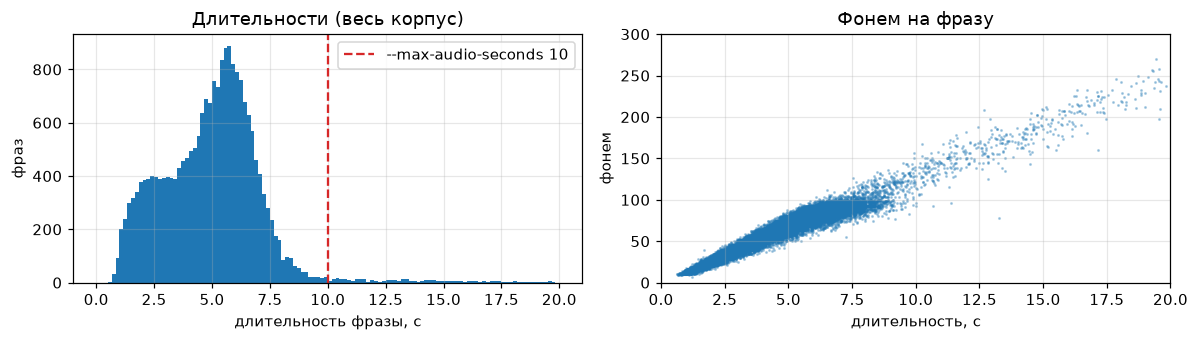

In [5]:
# длительность фраз и что отсекает фильтр --max-audio-seconds 10
gt_all["dur"] = [sf.info(str(WAVS / f"{i}.wav")).duration for i in gt_all.id]
gt_all["n_phones"] = gt_all.phones.str.split().str.len()
gt_all["test"] = gt_all.id.str[:6].astype(int) % 5 == 0
tr = gt_all[~gt_all.test]
kept = tr.dur <= 10
print(f"train: {len(tr)} фраз, {tr.dur.sum()/3600:.1f} ч; после отсечения >10 с: {kept.sum()} фраз "
      f"({kept.mean():.1%}), {tr.dur[kept].sum()/3600:.1f} ч")
print(f"фонем во фразе: медиана {tr.n_phones.median():.0f}, макс. среди оставленных {tr.n_phones[kept].max()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(gt_all.dur, bins=120, range=(0, 20), color="tab:blue")
ax[0].axvline(10, color="tab:red", ls="--", label="--max-audio-seconds 10")
ax[0].set(xlabel="длительность фразы, с", ylabel="фраз", title="Длительности (весь корпус)"); ax[0].legend()
ax[1].scatter(gt_all.dur, gt_all.n_phones, s=1, alpha=0.3)
ax[1].set(xlabel="длительность, с", ylabel="фонем", title="Фонем на фразу", xlim=(0, 20), ylim=(0, 300))
plt.tight_layout(); plt.show()

### 2.3. GT-фонемы и фонемы G2P

`metadata_phones_gt.csv` - фонемы из выравнивания MFA (то, что, по мнению MFA, произнёс диктор); `metadata_phones.csv` - то, что предсказывает наш модуль G2P из лабы 3 по тексту. На обучающей части они почти совпадают - G2P для известных слов берёт словарь, собранный из той же разметки, и расходится только в выборе вариантов произношения по контексту на тестовой части расходятся сильнее (там есть слова, которых нет в словаре).

In [6]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]

m = gt_all[["id", "phones", "test"]].merge(g2p_all[["id", "phones"]], on="id", suffixes=("_gt", "_g2p"))
rows = []
for part, sub in [("train", m[~m.test]), ("test", m[m.test])]:
    same = sub.phones_gt == sub.phones_g2p
    errs = sum(levenshtein(a.split(), b.split()) for a, b in zip(sub.phones_gt[~same], sub.phones_g2p[~same]))
    n = sub.phones_gt.str.split().str.len().sum()
    rows.append({"часть": part, "фраз": len(sub), "фраз с одинаковыми фонемами": f"{same.mean():.1%}",
                 "PER (G2P против GT)": round(errs / n, 4)})
display(pd.DataFrame(rows))
ex = m[(~m.test) & (m.phones_gt != m.phones_g2p)].iloc[:3]
for _, r in ex.iterrows():
    a, b = r.phones_gt.split(), r.phones_g2p.split()
    diff = [(i, x, y) for i, (x, y) in enumerate(zip(a, b)) if x != y][:4]
    print(r.id, "позиция, GT, G2P:", diff)

,часть,фраз,фраз с одинаковыми фонемами,PER (G2P против GT)
0,train,17475,86.8%,0.0029
1,test,4365,68.1%,0.0088


000013_RUSLAN позиция, GT, G2P: [(27, 'a', 'ə')]
000019_RUSLAN позиция, GT, G2P: [(8, 'ə', 'o')]
000026_RUSLAN позиция, GT, G2P: [(11, 'f', 'v')]


### 2.4. Оценочный набор

Выыданный `data/eval_sentences.csv` - 120 фраз из test-части, одинаковые у всех; его фонемы - из **официальной разметки v2**. Чтобы оценить модель так, как она будет работать в реальном тракте (текст → наш G2P → модель), `prepare_data.py` дополнительно пишет `data/eval_sentences_g2p.csv` - те же фразы с фонемами нашего G2P.

**Результат этапа:** все данные готовы; все фонемы - из `common/phones_mfa.txt`.

In [7]:
ev = read_meta("data/eval_sentences.csv")
ev_g2p = read_meta(DATA / "eval_sentences_g2p.csv")
ev["dur"] = [sf.info(str(WAVS / f"{i}.wav")).duration for i in ev.id]
print(f"eval_sentences.csv: {len(ev)} фраз, все номера делятся на 5: {(ev.id.str[:6].astype(int) % 5 == 0).all()}")
print(f"длительность {ev.dur.min():.2f}–{ev.dur.max():.2f} с, всего {ev.dur.sum()/60:.1f} мин; "
      f"различных фонем: {len(set(p for s in ev.phones for p in s.split()))}")
same_v2 = (ev.set_index("id").phones == read_meta(ROOT / "labs/lab3_g2p/data/metadata_phones_gt_v2.csv").set_index("id").phones.reindex(ev.id)).mean()
same_v3 = (ev.set_index("id").phones == gt_all.set_index("id").phones.reindex(ev.id)).mean()
same_g2p = (ev.phones.values == ev_g2p.phones.values).mean()
print(f"фонемы eval совпадают с GT v2: {same_v2:.1%}, с GT v3: {same_v3:.1%}, с нашим G2P: {same_g2p:.1%}")

eval_sentences.csv: 120 фраз, все номера делятся на 5: True
длительность 0.75–8.55 с, всего 8.9 мин; различных фонем: 55
фонемы eval совпадают с GT v2: 100.0%, с GT v3: 99.2%, с нашим G2P: 70.0%


## 3. Обучение: конфигурация и что пришлось исправить

Базовая конфигурация - выданный `train_fastspeech2.py` без изменений аудио-параметров (они диктуются вокодером лабы 5). Модель - coqui `ForwardTTS` в варианте FastSpeech 2: 37 млн параметров, энкодер и декодер по 6 FFT-блоков (self-attention с одной головой + свёрточный FFN), обучаемый выравниватель (*One TTS Alignment To Rule Them All*: forward-sum loss + MAS) вместо внешних длительностей. Ниже - фактический `config.json` основного запуска.

In [8]:
cfg = run_config("gt")
ma = cfg["model_args"]
rows = {
    "оптимизатор": f'{cfg["optimizer"]} {cfg["optimizer_params"]}',
    "lr / расписание": f'{cfg["lr"]}, {cfg["lr_scheduler"]} {cfg["lr_scheduler_params"]}, '
                       f'scheduler_after_epoch={cfg["scheduler_after_epoch"]}',
    "batch / shuffle": f'{cfg["batch_size"]} / {cfg["shuffle"]}',
    "grad_clip": cfg["grad_clip"],
    "точность": f'TF32={cfg["allow_tf32"]}, mixed_precision={cfg["mixed_precision"]}',
    "энкодер / декодер": f'{ma["encoder_type"]} {ma["encoder_params"]}, hidden {ma["hidden_channels"]}',
    "предсказатель длительности": f'{ma["duration_predictor_hidden_channels"]} кан., ядро {ma["duration_predictor_kernel_size"]}',
    "выравниватель / F0 / энергия": f'{ma["use_aligner"]} / {ma["use_pitch"]} / {ma["use_energy"]}',
    "веса лоссов": f'spec {cfg["spec_loss_alpha"]}, ssim {cfg["ssim_loss_alpha"]}, aligner {cfg["aligner_loss_alpha"]}, '
                   f'dur {cfg["dur_loss_alpha"]}, binary {cfg["binary_align_loss_alpha"]}',
    "аудио": ", ".join(f"{k}={cfg['audio'][k]}" for k in
                      ["sample_rate", "fft_size", "hop_length", "num_mels", "mel_fmax", "spec_gain", "log_func",
                       "signal_norm", "do_trim_silence"]),
}
display(pd.Series(rows, name="значение").to_frame())

,значение
оптимизатор,"Adam {'betas': [0.9, 0.998], 'weight_decay': 1e-06}"
lr / расписание,"0.0003, NoamLR {'warmup_steps': 4000}, scheduler_after_epoch=False"
batch / shuffle,16 / True
grad_clip,5.0
точность,"TF32=True, mixed_precision=False"
энкодер / декодер,"fftransformer {'hidden_channels_ffn': 1024, 'num_heads': 1, 'num_layers': 6, 'dropout_p': 0.1}, hidden 384"
предсказатель длительности,"256 кан., ядро 3"
выравниватель / F0 / энергия,True / False / False
веса лоссов,"spec 1.0, ssim 1.0, aligner 1.0, dur 0.1, binary 0.1"
аудио,"sample_rate=22050, fft_size=1024, hop_length=256, num_mels=80, mel_fmax=8000.0, spec_gain=1.0, log_func=np.log, signal_norm=False, do_tr..."


### 3.1. Найденные проблемы

Первые пробные запуски шли в 10–30 раз медленнее, чем можно, и с практически нулевой скоростью обучения. Причин оказалось несколько, все исправлены **флагами** скрипта (значения по умолчанию сохраняют выданное поведение, чтобы его можно было воспроизвести - запуск `shipped` ниже).

**1. Расписание Noam шагает раз в эпоху.** У тренера coqui по умолчанию `scheduler_after_epoch=True`, и `Fastspeech2Config` это не переопределяет. NoamLR считает «шаги» эпохами: разогрев (`warmup_steps=4000`) длится 4000 **эпох**, и фактический lr равен `lr × (эпоха+1) / 4000`. Именно поэтому README обещает речь только через 12–24 часа даже при `5e-3`. Флаг `--lr-schedule step` делает расписание пошаговым, как в Transformer и в статье FastSpeech 2 (там пик ≈ `384^-0.5 · 4000^-0.5 ≈ 8e-4`). Но с пошаговым расписанием выданный `lr=1e-3` оказался слишком большим - см. п. 7.

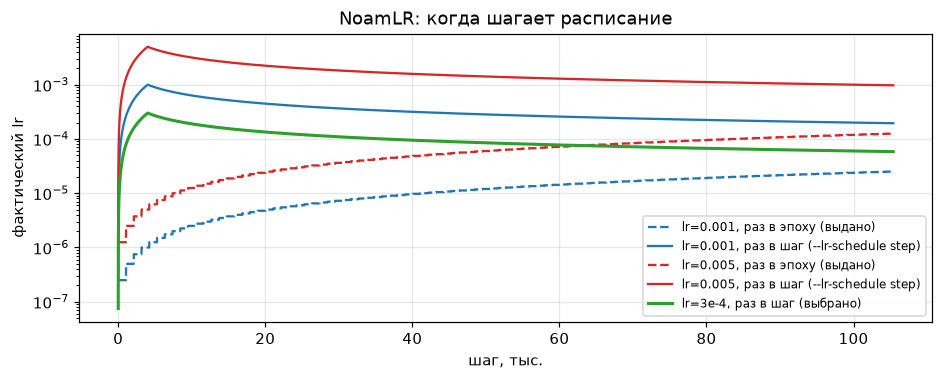

lr=0.0003: раз в эпоху — на 10-й эпохе 8.3e-07, на 100-й 7.6e-06; раз в шаг — пик 3.0e-04 на шаге 4000, на 100k 6.0e-05
lr=0.001: раз в эпоху — на 10-й эпохе 2.7e-06, на 100-й 2.5e-05; раз в шаг — пик 1.0e-03 на шаге 4000, на 100k 2.0e-04
lr=0.005: раз в эпоху — на 10-й эпохе 1.4e-05, на 100-й 1.3e-04; раз в шаг — пик 5.0e-03 на шаге 4000, на 100k 1.0e-03


In [ ]:
# эффективный lr: NoamLR(warmup=4000), шаг расписания раз в эпоху (как в выданном конфиге) и раз в шаг
def noam(lr, step, warmup=4000):
    step = np.maximum(step, 1)
    return lr * warmup**0.5 * np.minimum(step**-0.5, step * warmup**-1.5)

steps = np.arange(0, 100 * STEPS_PER_EPOCH)
fig, ax = plt.subplots(figsize=(10, 3.4))
for lr, c in [(1e-3, "tab:blue"), (5e-3, "tab:red")]:
    ax.plot(steps / 1000, noam(lr, steps // STEPS_PER_EPOCH + 1), c=c, ls="--", label=f"lr={lr:g}, раз в эпоху (выдано)")
    ax.plot(steps / 1000, noam(lr, steps + 1), c=c, label=f"lr={lr:g}, раз в шаг (--lr-schedule step)")
ax.plot(steps / 1000, noam(3e-4, steps + 1), c="tab:green", lw=2, label="lr=3e-4, раз в шаг (выбрано)")
ax.set(yscale="log", xlabel="шаг, тыс.", ylabel="фактический lr", title="NoamLR: когда шагает расписание")
ax.legend(fontsize=8); plt.show()
for lr in (3e-4, 1e-3, 5e-3):
    print(f"lr={lr:g}: раз в эпоху - на 10-й эпохе {noam(lr, 11):.1e}, на 100-й {noam(lr, 101):.1e}; "
          f"раз в шаг - пик {noam(lr, 4000):.1e} на шаге 4000, на 100k {noam(lr, 100_000):.1e}")

**2. Batch 32 не помещается в 8 ГБ.** Замер пикового расхода памяти на худшем батче (фразы по 10 с, 150 фонем), RTX 3070 Ti 8 ГБ:

| | B = 32 | B = 24 | B = 16 |
|---|---|---|---|
| fp32 / TF32 | 7,6 ГиБ, 5,9 с/шаг | 5,8 ГиБ, 1,2 с | **4,1 ГиБ, 0,30 с** |
| bf16 (autocast) | 6,1 ГиБ, 1,0 с | 4,7 ГиБ, 0,8 с | 3,3 ГиБ, 0,34 с |

При нехватке видеопамяти драйвер Windows не выдаёт OOM, а **молча переносит её в ОЗУ** (sysmem fallback) - шаг замедляется в 10–20 раз (5,9 с у B=32). Решение: **batch 16 + TF32** и `torch.cuda.set_per_process_memory_fraction(0.8)` (`--gpu-mem-fraction`): кэширующий аллокатор PyTorch из-за фрагментации на батчах разной длины резервирует до 6,2 ГиБ, а с ограничением он освобождает кэш вместо выхода за предел. bf16 на B=16 не быстрее, а риск численных проблем в выравнивателе есть - не используем. Шагов на эпоху стало 1054.

**3. Переподписка потоков в загрузчике.** Каждый из 8 воркеров `DataLoader` считает мел numpy-ем, и каждый по умолчанию запускает BLAS с 20 потоками - 160 потоков на 20-поточном CPU. Загрузка одного батча занимала 5–20 с, GPU простаивал (загрузка 0 %). `OMP/OPENBLAS/MKL_NUM_THREADS=1` (теперь выставляется в начале скрипта): **1–5 с/шаг → 0,19 с/шаг**, GPU загружен на 95 %.

**4. Батчи не перемешиваются.** `shuffle=False`, `batch_group_size=0`: датасет отсортирован по длине, и каждая эпоха идёт в одном и том же порядке - от самых коротких фраз к самым длинным. Градиенты внутри эпохи сильно коррелированы (видно по пилообразным кривым у `shipped` в разделе 6). Флаг `--shuffle`.

**5. Мелочи coqui, общие для всех запусков (не исправлялись; ошибка, ломающая внешние длительности, - в разделе 7):** SSIM-лосс фактически выключен (проверяется `hasattr(self, "ssim_loss")`, а атрибут называется `self.ssim`); «разгон» binary-alignment-лосса (`binary_loss_warmup_epochs=150`) масштабирует только записываемое в лог значение, в сумму лосс входит с весом 0,1 с первого шага; `max_seq_len=200` не используется (фильтр по тексту читает `max_text_len`, без ограничения) - отсекаются только фразы длиннее 10 с.

**6. Воркеры загрузчика пересоздаются каждую эпоху.** На Windows процессы `DataLoader` запускаются через `spawn`: каждый заново импортирует torch и coqui и получает копию датасета - это около 80 с простоя GPU на границе каждой эпохи (вместе с валидацией). При 1054 шагах (~3,3 мин) это ~25 % времени. Флаг `--persistent-workers` (подмена `DataLoader` в `base_tts` на `persistent_workers=True`) - эпоха **4,8 → 3,5 мин**.

**7. При `lr=1e-3` декодер выходит на плато.** Первый основной запуск (пошаговый Noam, пик 1e-3) за 23 тыс. шагов так и не сошёл с плато `loss_spec ≈ 3,5`: декодер выдаёт почти один и тот же средний спектр на любом входе, а выравниватель и предсказатель длительностей при этом учатся нормально. На 10 тыс. шагов его MCD (59,6 дБ) почти равна MCD постоянного мела (62,1), диапазон мела сжат до [-9,1; -2,9] против [-11,4; 0,5] у записи. Это известный режим post-LN трансформера при слишком большом шаге: градиенты в глубоких слоях затухают, и сеть застревает в тривиальном минимуме «предсказывать среднее». Короткие пробные запуски (3–4 тыс. шагов) с пиком 1e-4 и 3e-4 сходят с плато на ~2–2,7 тыс. шагов; выбран **3e-4** (быстрее, чем 1e-4, при той же устойчивости). Схлопнувшийся запуск сохранён как `lr1e-3` и участвует в сравнении скоростей обучения (раздел 6.2).

Итоговые флаги всех запусков, кроме `shipped`: `--lr 3e-4 --lr-schedule step --precision tf32 --batch-size 16 --shuffle --gpu-mem-fraction 0.8 --num-workers 6 --persistent-workers`.

### 3.2. Запуски

Бюджет - около суток GPU (RTX 3070 Ti 8 ГБ, i5-14600KF), поэтому запуски спланированы так, чтобы все сравнения шли **на равном числе шагов** (чекпоинт каждые 10 тыс. шагов). Запуски шли последовательно через очередь `run_queue.sh`.

In [10]:
RUN_INFO = {
    "gt":           "GT-фонемы v3, выравниватель, lr 3e-4/шаг",
    "g2p":          "G2P-фонемы, выравниватель, lr 3e-4/шаг (30 эпох + продолжение до 57)",
    "mfa_dur":      "GT-фонемы, длительности MFA (доп. 1), с исправлением collate",
    "mfa_dur_bug":  "то же до исправления: длительности перепутаны между фразами батча",
    "pitch_energy": "GT-фонемы, выравниватель + F0 + энергия (доп. 2)",
    "lr1e-3":       "GT, lr 1e-3/шаг (декодер схлопнулся, остановлен на 23k)",
    "lr1e-4":       "GT, lr 1e-4/шаг",
    "shipped":      "GT, выданная схема: lr 1e-3, расписание раз в эпоху, без shuffle",
}
scalars = {n: A.read_scalars(RUNS / n) for n in RUN_INFO if run_dir(n)}

def series(name, tag):
    df = scalars.get(name)
    if df is None:
        return pd.DataFrame(columns=["step", "value", "wall_time"])
    return df[df.tag == tag].sort_values("step")

rows = []
for n, desc in RUN_INFO.items():
    if n not in scalars:
        continue
    ep = series(n, "TrainEpochStats/epoch_time")
    evl = series(n, "EvalStats/avg_loss_spec")
    it = series(n, "TrainIterStats/loss")
    gaps = np.diff(np.sort(it.wall_time.values))
    wall = gaps[gaps < 600].sum() if len(it) else np.nan     # без перерыва между частями g2p
    rows.append({"запуск": n, "что": desc, "эпох": len(ep), "шагов": int(it.step.max()) if len(it) else 0,
                 "время, ч": round(wall / 3600, 2),
                 "с/шаг": round(series(n, "TrainEpochStats/avg_step_time").value.median(), 3),
                 "лучший eval loss_spec": round(evl.value.min(), 3) if len(evl) else np.nan})
runs_table = pd.DataFrame(rows)
display(runs_table)
print(f"всего GPU-времени: {runs_table['время, ч'].sum():.1f} ч на RTX 3070 Ti 8 ГБ")

,запуск,что,эпох,шагов,"время, ч",с/шаг,лучший eval loss_spec
0,gt,"GT-фонемы v3, выравниватель, lr 3e-4/шаг",80,84300,4.57,0.185,0.705
1,g2p,"G2P-фонемы, выравниватель, lr 3e-4/шаг (30 эпох + продолжение до 57)",58,61100,3.44,0.185,0.765
2,mfa_dur,"GT-фонемы, длительности MFA (доп. 1), с исправлением collate",30,31600,1.41,0.144,0.747
3,mfa_dur_bug,то же до исправления: длительности перепутаны между фразами батча,30,31600,1.39,0.144,3.370
4,pitch_energy,"GT-фонемы, выравниватель + F0 + энергия (доп. 2)",30,31600,1.76,0.188,0.493
5,lr1e-3,"GT, lr 1e-3/шаг (декодер схлопнулся, остановлен на 23k)",22,23200,1.74,0.195,3.545
6,lr1e-4,"GT, lr 1e-4/шаг",10,10500,0.57,0.185,0.808
7,shipped,"GT, выданная схема: lr 1e-3, расписание раз в эпоху, без shuffle",10,10500,0.56,0.129,3.604


всего GPU-времени: 15.4 ч на RTX 3070 Ti 8 ГБ


## 4. Кривые обучения основной модели

Сглаживание - экспоненциальное. Отдельно - **лосс предсказателя длительностей** и лосс выравнивателя: именно они показывают, сопоставила ли модель текст и звук.

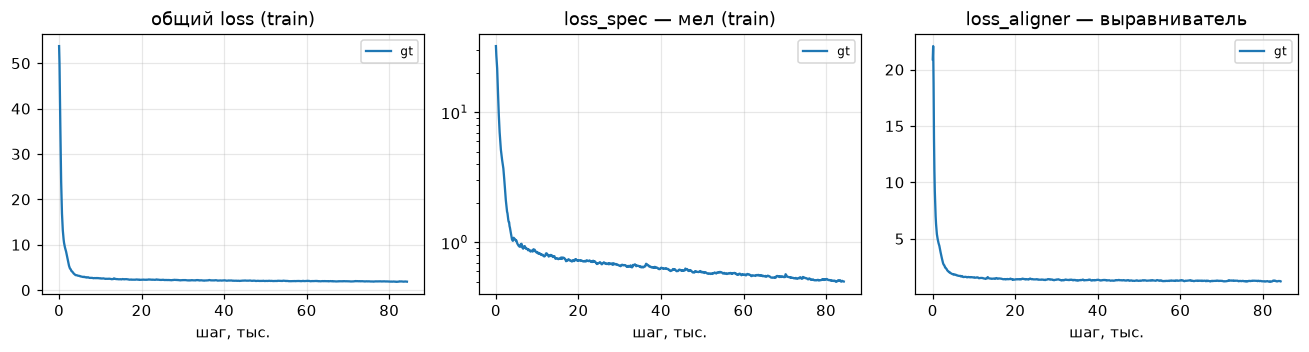

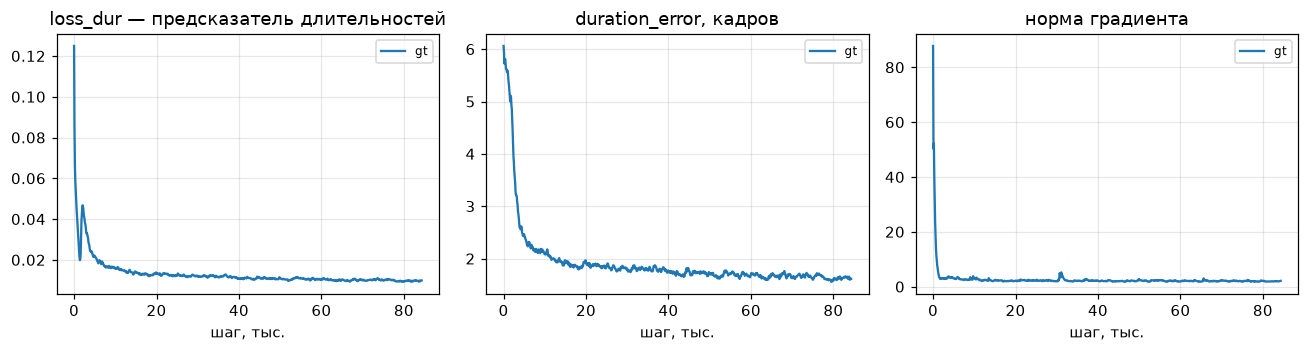

In [ ]:
def plot_runs(names, tags, titles, logy=("TrainIterStats/loss_spec", "EvalStats/avg_loss_spec"), alpha=0.8,
              xmax=None, figsize=(12, 3.3)):
    """TensorBoard пишет train-скаляры раз в 100 шагов; alpha=0.8 - сглаживание примерно по 500 шагам."""
    fig, axes = plt.subplots(1, len(tags), figsize=figsize)
    for ax, tag, title in zip(np.atleast_1d(axes), tags, titles):
        for n in names:
            s = series(n, tag)
            if len(s) == 0:
                continue
            y = A.smooth(s.value.values, alpha) if tag.startswith("TrainIter") else s.value.values
            ax.plot(s.step / 1000, y, label=n, marker=None if tag.startswith("TrainIter") else ".")
        ax.set(title=title, xlabel="шаг, тыс.")
        if tag in logy:
            ax.set_yscale("log")
        if xmax:
            ax.set_xlim(0, xmax)
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

plot_runs(["gt"], ["TrainIterStats/loss", "TrainIterStats/loss_spec", "TrainIterStats/loss_aligner"],
          ["общий loss (train)", "loss_spec - мел (train)", "loss_aligner - выравниватель"], logy=("TrainIterStats/loss_spec",))
plot_runs(["gt"], ["TrainIterStats/loss_dur", "TrainIterStats/duration_error", "TrainIterStats/grad_norm"],
          ["loss_dur - предсказатель длительностей", "duration_error, кадров", "норма градиента"])

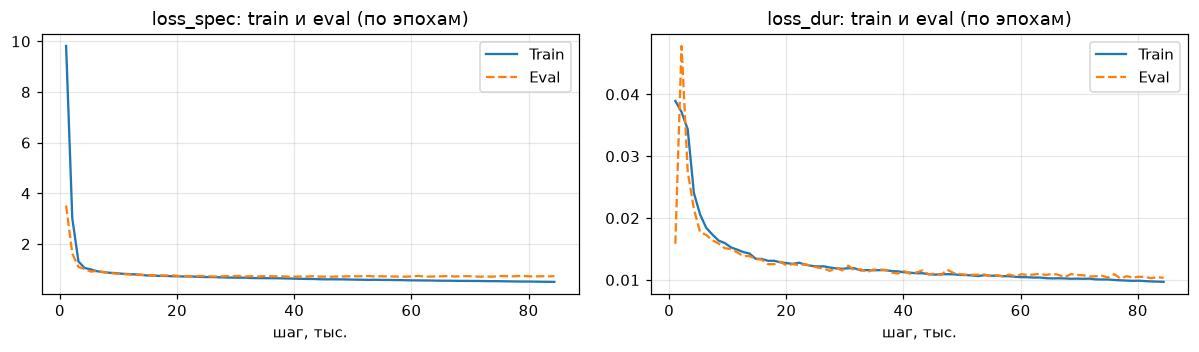

In [12]:
# train против eval (средние за эпоху)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for k, (tag, title) in enumerate([("avg_loss_spec", "loss_spec"), ("avg_loss_dur", "loss_dur")]):
    for part, ls in [("TrainEpochStats", "-"), ("EvalStats", "--")]:
        s = series("gt", f"{part}/{tag}")
        ax[k].plot(s.step / 1000, s.value, ls=ls, label=part.replace("Stats", "").replace("Epoch", ""))
    ax[k].set(title=f"{title}: train и eval (по эпохам)", xlabel="шаг, тыс."); ax[k].legend()
plt.tight_layout(); plt.show()

**Что видно на кривых.**

- **Плато в начале.** Первые ~2,5 тыс. шагов `loss_spec` стоит около 3,5: декодер выдаёт средний спектр (тот же режим, что в п. 7 раздела 3, но здесь кратковременный). На выходе с плато (≈ 2,6 тыс. шагов) `loss_dur` ненадолго **растёт** (0,03 → 0,04): целевые длительности для предсказателя даёт выравниватель, и в этот момент его выравнивание становится резким - цели меняются, предсказатель догоняет.
- **Дальше - плавная сходимость:** train `loss_spec` 0,81 на 10 тыс. шагов → 0,67 на 30 тыс. → ≈ 0,52 на 84 тыс.; ошибка длительностей - с 6 до ≈ 1,7 кадра на фонему; норма градиента после первых тысяч шагов ≈ 2–3, клиппинг (5) почти не срабатывает.
- **Train и eval.** До ~30 тыс. шагов кривые идут вместе, дальше eval `loss_spec` стоит на ≈ 0,70–0,72, а train продолжает снижаться: модель начинает запоминать обучающие фразы. Переобучение мягкое (лучший eval - на 73,85 тыс. шагов, 0,705), но выигрыш после 30 тыс. шагов мал: MCD на 30 тыс. - 28,49, у итоговой модели - 28,65. Разборчивость при этом всё же растёт (CER 2,9 % → 2,3 %, раздел 5.3) - MCD этого не замечает.
- `loss_dur` на eval держится на уровне train - предсказатель длительностей не переобучается.

## 5. Озвучивание отложенных предложений и оценка

`evaluate.py --run runs/<run> --metadata ../../data/metadata_phones_gt_train.csv --save-mels`: 120 фраз из `eval_sentences.csv` синтезируются по GT-фонемам; для каждой - `natural/` (запись), `copysynth/` (настоящий мел → Гриффин–Лим, потолок) и `model/` (мел модели → Гриффин–Лим). MCD считается **в мел-домене** (DTW-выравнивание по MFCC c1–c13): Гриффин–Лим не участвует. «Постоянный мел» - средний кадр обучающих данных на всю длину фразы. `--metadata` указывает на train-часть, чтобы средний кадр считался по обучающим, а не тестовым фразам (по умолчанию скрипт берёт первые 200 строк полного файла, где есть и test).

Абсолютные значения MCD здесь больше привычных 4–8 дБ из литературы: кепстр берётся DCT от натурального логарифма 80-полосного мела (а не SPTK-мел-кепстр), шкала другая. Сравнивать имеет смысл только относительные величины - модель против постоянного мела, модели между собой.

In [13]:
FAV = "gt"              # любимая модель
FAV_EVAL = "eval"            # GT-фонемы eval_sentences.csv
def load_eval(run, out):
    d = RUNS / run / out
    if not (d / "mcd.csv").exists():
        return None
    df = pd.read_csv(d / "mcd.csv", sep="|", dtype={"id": str})
    rng = []
    for i in df.id:
        nat = np.load(d / "mels" / f"{i}_natural.npy"); mod = np.load(d / "mels" / f"{i}_model.npy")
        rng.append((nat.min(), nat.max(), mod.min(), mod.max(), A.harmonic_ripple(nat), A.harmonic_ripple(mod)))
    df[["nat_min", "nat_max", "mod_min", "mod_max", "nat_ripple", "mod_ripple"]] = rng
    df["ratio"] = df.frames_model / df.frames_natural
    df.attrs["dir"] = d
    return df

def eval_summary(df, label):
    return {"модель": label, "MCD модели, дБ": round(df.mcd_model.mean(), 2),
            "медиана": round(df.mcd_model.median(), 2), "MCD пост. мела, дБ": round(df.mcd_constant.mean(), 2),
            "доля фраз, где модель лучше пост. мела": f"{(df.mcd_model < df.mcd_constant).mean():.0%}",
            "кадры модель/запись": round(df.ratio.mean(), 3),
            "мел natural [min, max]": f"[{df.nat_min.mean():.2f}, {df.nat_max.mean():.2f}]",
            "мел модели [min, max]": f"[{df.mod_min.mean():.2f}, {df.mod_max.mean():.2f}]",
            "гармоники: рябь модели / записи": f"{df.mod_ripple.mean():.2f} / {df.nat_ripple.mean():.2f}"}

fav = load_eval(FAV, FAV_EVAL)
display(pd.DataFrame([eval_summary(fav, f"{FAV} ({FAV_EVAL})")]).T.rename(columns={0: "значение"}))

,значение
модель,gt (eval)
"MCD модели, дБ",28.65
медиана,28.01
"MCD пост. мела, дБ",62.13
"доля фраз, где модель лучше пост. мела",100%
кадры модель/запись,0.932
"мел natural [min, max]","[-11.39, 0.48]"
"мел модели [min, max]","[-11.04, -0.59]"
гармоники: рябь модели / записи,0.26 / 1.04


In [14]:
# критерии приёмки
nat_rng = fav.nat_max.mean() - fav.nat_min.mean(); mod_rng = fav.mod_max.mean() - fav.mod_min.mean()
checks = {
    "все 120 предложений синтезированы": len(fav) == 120 and len(list((fav.attrs["dir"] / "model").glob("*.wav"))) == 120,
    "MCD модели ниже MCD постоянного мела": fav.mcd_model.mean() < fav.mcd_constant.mean(),
    "диапазон мела сопоставим с настоящим (размах ±15 %, границы ±1,5)":
        abs(mod_rng / nat_rng - 1) < 0.15 and abs(fav.mod_min.mean() - fav.nat_min.mean()) < 1.5
        and abs(fav.mod_max.mean() - fav.nat_max.mean()) < 1.5,
}
display(pd.Series(checks, name="выполнено").to_frame())

,выполнено
все 120 предложений синтезированы,True
MCD модели ниже MCD постоянного мела,True
"диапазон мела сопоставим с настоящим (размах ±15 %, границы ±1,5)",True


### 5.1. Спектрограммы и прослушивание

Итоговая модель - `gt` (лучший по eval чекпоинт, 73,85 тыс. шагов). Все критерии приёмки выполнены (таблица выше).

**Спектрограммы.** Модель воспроизводит сегментацию (паузы и границы звуков на тех же местах, что в записи, с поправкой на темп) и **форманты**. Чего у неё нет так это **гармоник**: в записи нижние 20–30 полос исчерчены горизонтальными линиями с шагом F0, у модели там гладкая огибающая. Кроме того, спектр модели размыт по времени и слабее на высоких частотах. Это типичное over-smoothing неавторегрессионной модели с L1-лоссом: высота тона по фонемам не определена, и модель выдаёт усреднение спектров с разными F0, в котором гармоники гасят друг друга.

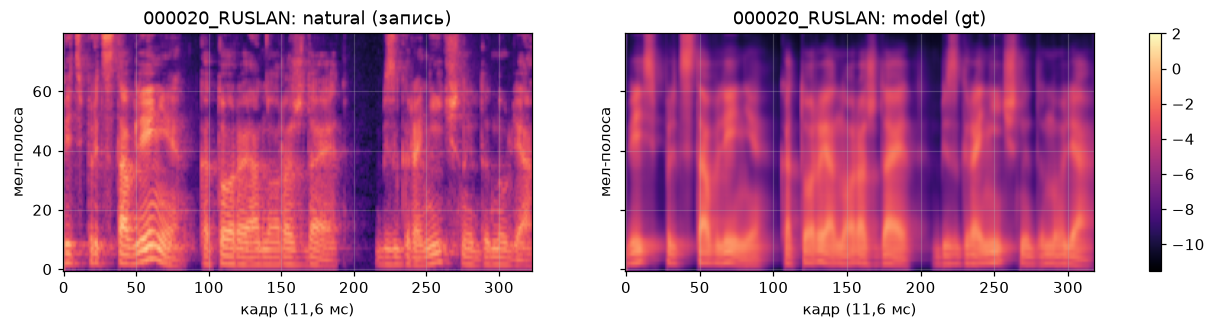

Ведь представления, которые оно рождает, безграничны до нуля.
natural


copysynth


model


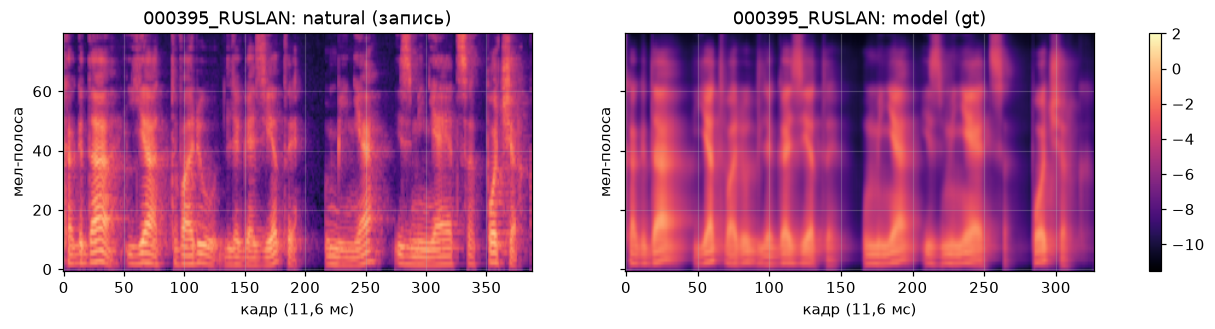

Когда я творю для газеты, у меня изменяется почерк.
natural


copysynth


model


In [15]:
SHOW = ["000020_RUSLAN", "000395_RUSLAN"]   # повествовательная фраза и фраза с перечислением
for uid in SHOW:
    d = fav.attrs["dir"]
    nat = np.load(d / "mels" / f"{uid}_natural.npy"); mod = np.load(d / "mels" / f"{uid}_model.npy")
    fig, ax = plt.subplots(1, 2, figsize=(13, 2.8), sharey=True)
    for a, m_, t in [(ax[0], nat, "natural (запись)"), (ax[1], mod, f"model ({FAV})")]:
        im = a.imshow(m_, origin="lower", aspect="auto", vmin=-11.5, vmax=2, cmap="magma")
        a.set(title=f"{uid}: {t}", xlabel="кадр (11,6 мс)", ylabel="мел-полоса")
    plt.colorbar(im, ax=ax, fraction=0.02); plt.show()
    print(ev.set_index("id").text[uid])
    for sub in ["natural", "copysynth", "model"]:
        print(sub); display(Audio(str(d / sub / f"{uid}.wav")))

### 5.2. Акустическое сравнение natural / copysynth / model

Чтобы сравнить три варианта в одной области, мел снимается заново **со всех трёх wav** тем же `AudioProcessor`. Тогда MCD «copysynth против natural» - это вклад Гриффина–Лима, а «model против natural» - вклад GL плюс модели. Ниже - средние спектры (LTAS).

MCD почти не чувствует **гармоник** в нижних мел-полосах (шаг ≈ F0). Поэтому в сводных таблицах есть ещё одна величина - **«рябь»**: среднее |вторая разность по частоте| лог-мела в полосах 0–29 (до ≈ 1,1 кГц), по 50 % самых громких кадров (`analysis.harmonic_ripple`). У гладкой огибающей она близка к нулю, у записи ≈ 1,0.

,copysynth vs natural,model vs natural,model (мел модели) vs natural
mean,41.22,51.99,28.65
50%,40.79,51.86,28.01
std,2.46,4.56,2.86


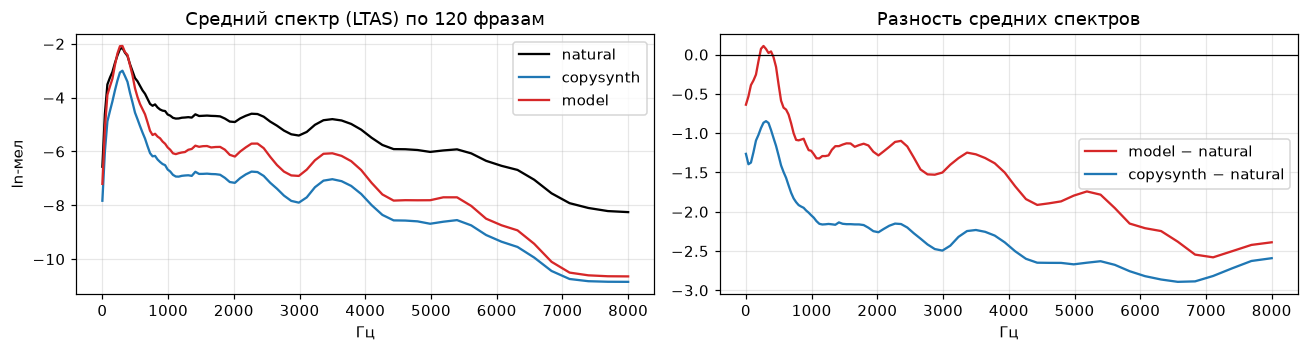

In [ ]:
# акустическое сравнение в одной и той же ауди-области: мел, снятый заново с wav всех трёх вариантов
from TTS.utils.audio import AudioProcessor
from train_fastspeech2 import build_audio_config
ap = AudioProcessor.init_from_config(build_audio_config())

def wav_mel(path):
    return ap.melspectrogram(ap.load_wav(str(path)))

d = fav.attrs["dir"]
rows, ltas = [], {k: [] for k in ["natural", "copysynth", "model"]}
for uid in fav.id:
    mels = {k: wav_mel(d / k / f"{uid}.wav") for k in ltas}
    for k in ltas:
        ltas[k].append(mels[k].mean(axis=1))
    rows.append({"id": uid,
                 "copysynth vs natural": mcd(mels["natural"], mels["copysynth"]),
                 "model vs natural": mcd(mels["natural"], mels["model"]),
                 "model (мел модели) vs natural": fav.set_index("id").mcd_model[uid]})
acoustic = pd.DataFrame(rows)
display(acoustic.drop(columns="id").describe().loc[["mean", "50%", "std"]].round(2))

freqs = librosa.mel_frequencies(n_mels=80, fmin=0, fmax=8000)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
for k, c in [("natural", "k"), ("copysynth", "tab:blue"), ("model", "tab:red")]:
    ax[0].plot(freqs, np.mean(ltas[k], axis=0), c=c, label=k)
ax[0].set(xlabel="Гц", ylabel="ln-мел", title="Средний спектр (LTAS) по 120 фразам"); ax[0].legend()
ax[1].plot(freqs, np.mean(ltas["model"], axis=0) - np.mean(ltas["natural"], axis=0), c="tab:red", label="model − natural")
ax[1].plot(freqs, np.mean(ltas["copysynth"], axis=0) - np.mean(ltas["natural"], axis=0), c="tab:blue", label="copysynth − natural")
ax[1].axhline(0, c="k", lw=0.8); ax[1].set(xlabel="Гц", title="Разность средних спектров"); ax[1].legend()
plt.tight_layout(); plt.show()

**Наблюдения.**

- Сам Гриффин–Лим вносит очень большую ошибку: MCD copysynth против записи ≈ 41 дБ, больше, чем вся ошибка модели в мел-домене (28,7). Поэтому сравнивать модели нужно по их мелам (столбец «мел модели»), а wav-оценки - только относительно copysynth.
- **LTAS.** Copysynth ниже записи на 1–3 единицы ln-мела по всему диапазону, и тем сильнее, чем выше частота. Уровень не сохраняется в самом восстановлении: перед GL амплитуды возводятся в степень `power=1,5` (это подчёркивает пики и опускает всё между ними), а 60 итераций не дают согласованной фазы, и соседние кадры частично гасят друг друга при наложении окон. Синтез модели теряет меньше (0–1,5 ниже 4 кГц), вероятно потому, что гладкий спектр без гармоник содержит меньше провалов, которые степень углубляет. Выше 4 кГц разница с записью у модели почти такая же, как у copysynth, - там к потерям GL добавляется собственный недобор высоких частот (фрикативные, взрывы).

### 5.3. Фонетическое качество

Два независимых измерения:

1. **Длительности фонем** - то, что модель решает сама (длительности предсказываются по тексту). Предсказанные длительности сравниваются с выравниванием MFA v3 тех же фраз (там, где фонемы eval-набора совпадают с выравниванием).
2. **Разборчивость** - автоматическое распознавание синтеза моделью Whisper (large-v3-turbo) и CER/WER относительно текста (`asr_eval.py`). Запись (`natural`) и `copysynth` дают ориентиры: первая - потолок ASR, вторая - сколько разборчивости съедает сам Гриффин–Лим.

In [17]:
# длительности: предсказанные моделью против выравнивания MFA (v3) на тех же фонемах
from praatio import textgrid
def mfa_durations(uid):
    tg = textgrid.openTextgrid(str(DATA / "mfa/align_v3" / f"{uid}.TextGrid"), True)
    hop = 256 / 22050
    return [(unicodedata.normalize("NFC", e.label) or "<SIL>", (e.end - e.start) / hop) for e in tg.tiers[1].entries]

def duration_table(eval_dir, eval_csv="data/eval_sentences.csv"):
    evs = read_meta(eval_csv).set_index("id")
    recs = []
    for uid in evs.index:
        ph = evs.phones[uid].split()
        ref = mfa_durations(uid)
        f = eval_dir / "mels" / f"{uid}_durations.npy"
        if not f.exists() or [p for p, _ in ref] != ph:
            continue                       # фонемы eval (v2) и выравнивание v3 должны совпасть
        pred = np.load(f)
        for p, (_, r), q in zip(ph, ref, pred):
            recs.append((uid, p, r, q))
    return pd.DataFrame(recs, columns=["id", "phone", "ref", "pred"])

VOW = set("a e i o u æ ɐ ə ɛ ɨ ɪ ɵ ʉ ʊ".split())
def duration_report(dt, label):
    cls = np.where(dt.phone == "<SIL>", "пауза", np.where(dt.phone.isin(VOW), "гласная", "согласная"))
    out = []
    for c in ["гласная", "согласная", "пауза"]:
        s = dt[cls == c]
        out.append({"модель": label, "класс": c, "фонем": len(s),
                    "MFA, мс": round(s.ref.mean() * 11.61, 1), "модель, мс": round(s.pred.mean() * 11.61, 1),
                    "MAE, мс": round((s.pred - s.ref).abs().mean() * 11.61, 1),
                    "корр.": round(np.corrcoef(s.ref, s.pred)[0, 1], 3)})
    return out

dur_fav = duration_table(fav.attrs["dir"])
print(f"фраз, где фонемы eval совпали с выравниванием v3: {dur_fav.id.nunique()} из 120")
display(pd.DataFrame(duration_report(dur_fav, FAV)))

фраз, где фонемы eval совпали с выравниванием v3: 55 из 120


,модель,класс,фонем,"MFA, мс","модель, мс","MAE, мс",корр.
0,gt,гласная,1218,53.4,73.300003,33.2,0.467
1,gt,согласная,1691,82.5,62.900002,37.8,0.286
2,gt,пауза,118,111.4,88.199997,78.4,0.332


In [18]:
# ASR-разборчивость (Whisper large-v3-turbo): CER/WER относительно текста
asr_path = RUNS / "asr_results.csv"
if asr_path.exists():
    asr = pd.read_csv(asr_path, sep="|", dtype=str)
    asr[["cer", "wer"]] = asr[["cer", "wer"]].astype(float)
    display(asr.groupby(["run", "variant"])[["cer", "wer"]].mean().round(3).sort_values("cer"))
else:
    print("asr_results.csv ещё не посчитан")

cer    wer
run                variant                
gt                 natural    0.017  0.051
                   copysynth  0.020  0.061
mfa_dur@30k        model      0.020  0.070
pitch_energy@30k   model      0.021  0.073
gt                 model      0.023  0.075
g2p@60k            model      0.024  0.089
gt/g2p-фонемы      model      0.025  0.080
gt@40k/g2p-фонемы  model      0.026  0.086
gt@40k             model      0.026  0.089
gt@30k/g2p-фонемы  model      0.028  0.093
g2p@60k/g2p-фонемы model      0.029  0.097
gt@30k             model      0.029  0.091
g2p@50k            model      0.033  0.106
lr1e-4@10k         model      0.037  0.112
g2p@40k            model      0.037  0.125
gt@10k             model      0.053  0.161
g2p@30k/g2p-фонемы model      0.182  0.424
g2p@30k            model      0.185  0.440
mfa_dur_bug@30k    model      0.904  1.051
lr1e-3@10k         model      0.946  1.049
shipped@10k        model      1.000  1.236

**Длительности.** Модель в целом говорит на ~7 % быстрее записи (кадры модель/запись 0,93), но картина по классам неоднородна: гласные у неё **длиннее**, чем по MFA (73 мс против 53), согласные короче (63 против 82), паузы короче (88 против 111); корреляция с MFA по отдельным фонемам - 0,3–0,5. Большая часть этого расхождения - не ошибка предсказателя, а **разные разметчики**: модель учится на длительностях своего выравнивателя, который ставит границу «согласный–гласный» иначе, чем MFA (отдаёт переходные участки гласной). Это подтверждает доп. задание 1 (раздел 7): обученная на длительностях MFA модель воспроизводит их с корреляцией 0,77–0,85. Общий для всех моделей результат - **паузы предсказываются хуже всего** (корр. ≈ 0,33): их длина зависит от синтаксиса и дыхания, а не от соседних фонем, и сжатие пауз даёт основную часть «ускорения» речи.

**Разборчивость.** Запись распознаётся с CER 1,7 % (WER 5,1 %; это не ошибки диктора, а нормализация: Whisper пишет числа цифрами - «1942» вместо «тысяча девятьсот сорок втором» - и путает редкие фамилии: «Ванемуйне», «Хуриев»), copysynth - 2,0 %: Гриффин–Лим разборчивость почти не портит. Итоговая модель `gt` - **CER 2,3 %, WER 7,5 %**, то есть почти на уровне собственного потолка (copysynth). С фонемами нашего G2P (реальный тракт текст → G2P → модель) - 2,5 % / 8,0 %: ошибки G2P (раздел 2.3) почти не сказываются. Разборчивость растёт с обучением и после того, как MCD перестаёт меняться: 5,3 % на 10 тыс. шагов, 2,9 % на 30 тыс., 2,3 % у итоговой.

### 5.4. Мелодическое (интонационное) качество

F0 извлекается pYIN (50–300 Гц, сетка кадров мела) из всех трёх wav. Сравниваются: средний F0, разброс F0 в полутонах (СКО и размах 5–95 %) - живость интонации, - и совпадение контуров с записью вдоль DTW-пути (корреляция и RMSE в полутонах по кадрам, вокализованным в обоих, и точность решения «тон есть / тона нет»). Пара «copysynth против natural» показывает, насколько сам Гриффин–Лим искажает оценку F0.

In [ ]:
# F0 (pYIN, 50–300 Гц) для natural / copysynth / model; сопоставление по DTW-пути на мелах
def f0_table(eval_dir, run_label):
    paths = {(uid, k): eval_dir / k / f"{uid}.wav" for uid in read_meta("data/eval_sentences.csv").id
             for k in ["natural", "copysynth", "model"] if (eval_dir / k / f"{uid}.wav").exists()}
    cache = eval_dir / "f0_cache.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)["f0"].item()
    else:
        z = A.f0_contours(paths, workers=4)
        np.savez_compressed(cache, f0=np.array(z, dtype=object))
    rows, per = [], []
    for uid in sorted({u for u, _ in z}):
        nat_mel = np.load(eval_dir / "mels" / f"{uid}_natural.npy")
        mod_mel = np.load(eval_dir / "mels" / f"{uid}_model.npy")
        ia, ib = dtw_align(mel_to_mfcc(nat_mel), mel_to_mfcc(mod_mel))
        for k in ["natural", "copysynth", "model"]:
            s = A.f0_summary(z[(uid, k)]); s.update(id=uid, variant=k, run=run_label); rows.append(s)
        agr = A.f0_agreement(z[(uid, "natural")], z[(uid, "model")], ia, ib); agr.update(id=uid, run=run_label, pair="model vs natural"); per.append(agr)
        n = min(len(z[(uid, "natural")]), len(z[(uid, "copysynth")]))
        idx = np.arange(n)
        agr = A.f0_agreement(z[(uid, "natural")], z[(uid, "copysynth")], idx, idx); agr.update(id=uid, run=run_label, pair="copysynth vs natural"); per.append(agr)
    return pd.DataFrame(rows), pd.DataFrame(per), z

f0_fav, f0_agr_fav, f0z_fav = f0_table(fav.attrs["dir"], FAV)
def f0_agg(df, by):
    """Средние по фразам; F0-статистики - только по фразам, где pYIN нашёл ≥ 5 вокализованных кадров."""
    g = df.groupby(by)
    out = g[["voiced", "f0_mean", "f0_std_st", "f0_range_st"]].mean().round(2)
    out.insert(1, "фраз с F0", g.f0_mean.count())
    return out

display(f0_agg(f0_fav, "variant")
        .rename(columns={"voiced": "доля вокализ.", "f0_mean": "средний F0, Гц", "f0_std_st": "СКО F0, полутона",
                         "f0_range_st": "размах 5–95 %, полутона"}))
agr_tab = f0_agr_fav.groupby("pair")[["f0_corr", "f0_rmse_st", "vuv_acc"]].mean().round(3)
agr_tab.insert(0, "фраз с общими вокализ. кадрами", f0_agr_fav.groupby("pair").f0_corr.count())
display(agr_tab)

,доля вокализ.,фраз с F0,"средний F0, Гц","СКО F0, полутона","размах 5–95 %, полутона"
variant,,,,,
copysynth,0.35,119,140.64,3.83,11.82
model,0.00,10,122.43,0.37,0.96
natural,0.38,118,123.75,3.14,10.23


,фраз с общими вокализ. кадрами,f0_corr,f0_rmse_st,vuv_acc
pair,,,,
copysynth vs natural,116,0.875,1.169,0.850
model vs natural,3,0.140,14.775,0.622


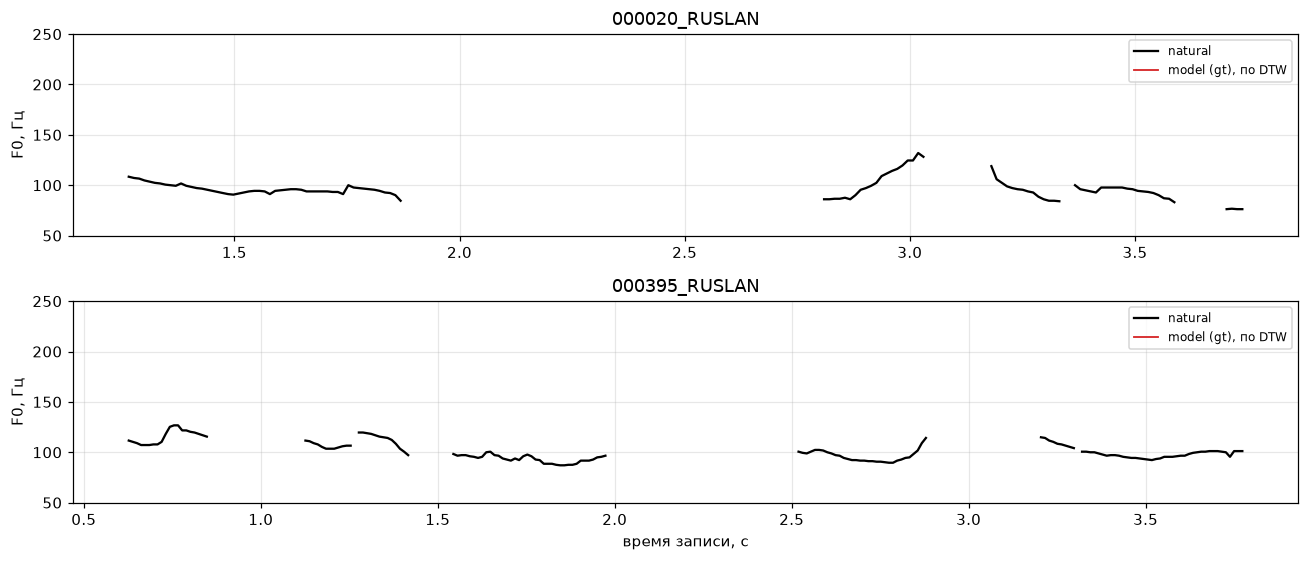

In [20]:
fig, axes = plt.subplots(len(SHOW), 1, figsize=(12, 2.6 * len(SHOW)))
for ax, uid in zip(np.atleast_1d(axes), SHOW):
    nat_mel = np.load(fav.attrs["dir"] / "mels" / f"{uid}_natural.npy")
    mod_mel = np.load(fav.attrs["dir"] / "mels" / f"{uid}_model.npy")
    ia, ib = dtw_align(mel_to_mfcc(nat_mel), mel_to_mfcc(mod_mel))
    fn, fm = f0z_fav[(uid, "natural")], f0z_fav[(uid, "model")]
    x = np.arange(len(fn)) * 0.01161
    ax.plot(x, np.where(fn > 0, fn, np.nan), "k", lw=1.5, label="natural")
    # контур модели, перенесённый на время записи по DTW-пути
    warped = np.full(len(fn), np.nan)
    for i, j in zip(ia, ib):
        if i < len(fn) and j < len(fm) and fm[j] > 0:
            warped[i] = fm[j]
    ax.plot(x, warped, "tab:red", lw=1.2, label=f"model ({FAV}), по DTW")
    ax.set(title=uid, ylabel="F0, Гц", ylim=(50, 250)); ax.legend(fontsize=8)
axes[-1].set_xlabel("время записи, с"); plt.tight_layout(); plt.show()

**У основной модели интонации нет - тона нет вообще.** pYIN находит вокализованные кадры в 38 % кадров записи и в 35 % у copysynth (Гриффин–Лим тон сохраняет: корреляция контуров 0,88, расхождение 1,2 полутона), а в синтезе модели - практически ни одного (несколько фраз с единичными ложными срабатываниями, поэтому средний F0 и разброс у строки `model` неинформативны, а на графике контура модели почти нет). Это прямое следствие отсутствия гармоник (раздел 5.1): из гладкой огибающей Гриффин–Лим восстанавливает непериодический, шумоподобный сигнал. Периодичности, по которой pYIN ищет тон, в нём нет, хотя слова разборчивы (CER 2,3 %). Получить интонацию можно, только подав высоту тона декодеру явно

## 6. Сравнения

Все сравнения - **на равном числе шагов** (`checkpoint_<N>.pth`), на одних и тех же 120 фразах.

In [21]:
# сравнения на равном числе шагов: evaluate.py по checkpoint_<N>.pth в runs/<run>/eval_<N>[_g2p]
def eval_at(run, step, g2p=False):
    return load_eval(run, f"eval_{step // 1000}k" + ("_g2p" if g2p else ""))

def summary_rows(spec):
    out = []
    for label, run, step, g2p in spec:
        df = eval_at(run, step, g2p)
        if df is not None:
            out.append(eval_summary(df, label))
    return pd.DataFrame(out)

### 6.1. Обязательное сравнение: обучение на GT-фонемах и на фонемах G2P

`gt` и `g2p` отличаются только обучающими метаданными. Каждую модель оцениваем на eval-фразах в двух вариантах фонем: GT (выданный `eval_sentences.csv`) и G2P (`eval_sentences_g2p.csv`).

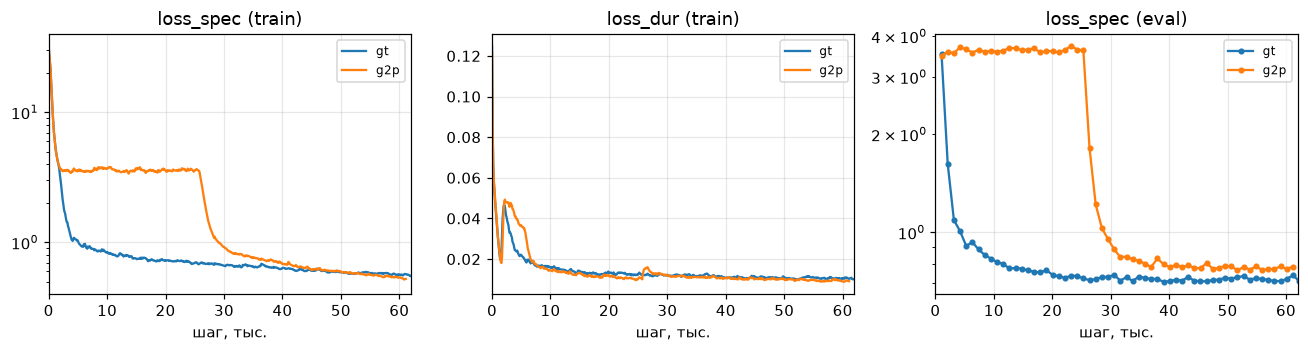

выход с плато (среднее train loss_spec за 1000 шагов < 2,0): gt — 2.6k, g2p — 26.8k, lr1e-4 — 3.7k, mfa_dur — 1.4k, pitch_energy — 2.5k


In [ ]:
plot_runs(["gt", "g2p"], ["TrainIterStats/loss_spec", "TrainIterStats/loss_dur", "EvalStats/avg_loss_spec"],
          ["loss_spec (train)", "loss_dur (train)", "loss_spec (eval)"], xmax=62)

def escape_step(run, level=2.0, window_steps=1000):
    """Первый шаг, на котором среднее train loss_spec за window_steps шагов опустилось ниже level (выход с плато)."""
    s = series(run, "TrainIterStats/loss_spec")
    n = max(1, int(round(window_steps / np.median(np.diff(s.step)))))   # TensorBoard пишет не каждый шаг
    m = s.value.rolling(n, min_periods=n).mean()
    hit = s.step[m < level]
    return int(hit.iloc[0]) if len(hit) else None

esc = {n: escape_step(n) for n in ["gt", "g2p", "lr1e-4", "mfa_dur", "pitch_energy"]}
print("выход с плато (среднее train loss_spec за 1000 шагов < 2,0):",
      ", ".join(f"{n} - {'нет' if s is None else f'{s / 1000:.1f}k'}" for n, s in esc.items()))

In [ ]:
# 1) на равном числе шагов (30k) - как планировалось 2) на сопоставимом числе шагов ПОСЛЕ выхода с плато
spec = [
    ("gt@30k, eval-фонемы GT",   "gt",  30000, False),
    ("gt@30k, eval-фонемы G2P",  "gt",  30000, True),
    ("g2p@30k, eval-фонемы GT",  "g2p", 30000, False),
    ("g2p@30k, eval-фонемы G2P", "g2p", 30000, True),
    ("gt@40k, eval-фонемы GT",   "gt",  40000, False),
    ("gt@40k, eval-фонемы G2P",  "gt",  40000, True),
    ("g2p@40k, eval-фонемы GT",  "g2p", 40000, False),
    ("g2p@50k, eval-фонемы GT",  "g2p", 50000, False),
    ("g2p@60k, eval-фонемы GT",  "g2p", 60000, False),
    ("g2p@60k, eval-фонемы G2P", "g2p", 60000, True),
]
tab = summary_rows(spec)
after = {lbl: (st - esc[run]) / 1000 for lbl, run, st, _ in spec if esc.get(run) is not None}
tab.insert(1, "шагов после плато, тыс.", tab["модель"].map(after).round(1))
# разборчивость: метки asr_results.csv вида «g2p@60k» и «g2p@60k/g2p-фонемы»
asr_m = asr[asr.variant == "model"].groupby("run")[["cer", "wer"]].mean()
asr_lbl = {lbl: f"{run}@{st // 1000}k" + ("/g2p-фонемы" if g else "") for lbl, run, st, g in spec}
for col in ["cer", "wer"]:
    tab[f"{col.upper()}, %"] = tab["модель"].map(lambda l: round(100 * asr_m[col].get(asr_lbl[l], np.nan), 1))
display(tab.drop(columns=["MCD пост. мела, дБ", "доля фраз, где модель лучше пост. мела", "мел natural [min, max]"]))

,модель,"шагов после плато, тыс.","MCD модели, дБ",медиана,кадры модель/запись,"мел модели [min, max]",гармоники: рябь модели / записи,"CER, %","WER, %"
0,"gt@30k, eval-фонемы GT",27.4,28.49,27.96,0.918,"[-11.03, -0.75]",0.24 / 1.04,2.9,9.1
1,"gt@30k, eval-фонемы G2P",27.4,28.58,28.09,0.917,"[-11.03, -0.74]",0.24 / 1.04,2.8,9.3
2,"g2p@30k, eval-фонемы GT",3.2,32.90,32.50,0.886,"[-11.19, -1.15]",0.18 / 1.04,18.5,44.0
3,"g2p@30k, eval-фонемы G2P",3.2,32.96,32.59,0.887,"[-11.18, -1.15]",0.18 / 1.04,18.2,42.4
4,"gt@40k, eval-фонемы GT",37.4,28.60,28.06,0.924,"[-11.01, -0.77]",0.23 / 1.04,2.6,8.9
5,"gt@40k, eval-фонемы G2P",37.4,28.69,28.22,0.924,"[-11.01, -0.76]",0.23 / 1.04,2.6,8.6
6,"g2p@40k, eval-фонемы GT",13.2,29.05,28.72,0.931,"[-11.23, -0.79]",0.22 / 1.04,3.7,12.5
7,"g2p@50k, eval-фонемы GT",23.2,28.86,28.29,0.918,"[-11.30, -0.70]",0.24 / 1.04,3.3,10.6
8,"g2p@60k, eval-фонемы GT",33.2,28.50,28.08,0.941,"[-11.19, -0.72]",0.26 / 1.04,2.4,8.9
9,"g2p@60k, eval-фонемы G2P",33.2,28.54,28.09,0.942,"[-11.18, -0.71]",0.26 / 1.04,2.9,9.7


**На 30 тыс. шагов сравнение нечестное.** `g2p` с теми же настройками простоял на плато «среднего спектра» 26,8 тыс. шагов (у `gt` - 2,6 тыс.) и к 30 тыс. учился нормально всего ~3 тыс. шагов: MCD 32,9, CER 18 %. Это не свойство фонем G2P, а случайность выхода с плато (раздел 6.2, вывод 2 в разделе 9). Показательно, что `loss_dur` у `g2p` сошёлся так же быстро, как у `gt` (к ~7 тыс. шагов): выравниватель своё дело сделал, а декодер ещё ~20 тыс. шагов оставался в минимуме «среднего спектра». Поэтому `g2p` продолжен с того же чекпоинта (`--continue-path`: веса, оптимизатор, расписание lr и счётчик шагов) до 60 тыс., и модели сравниваются по **числу шагов после выхода с плато** (столбец таблицы).

| модель | шагов после плато | MCD | CER, eval-фонемы GT | CER, eval-фонемы G2P |
|---|---|---|---|---|
| `gt`@30k | 27,4 тыс. | 28,49 | 2,9 % | 2,8 % |
| `gt`@40k | 37,4 тыс. | 28,60 | 2,6 % | 2,6 % |
| `g2p`@60k | 33,2 тыс. | 28,50 | 2,4 % | 2,9 % |

- **При равном «полезном» обучении модели равны.** `g2p`@60k находится между `gt`@30k и `gt`@40k по числу шагов после плато, и по MCD (28,50 против 28,49 / 28,60), и по разборчивости (CER 2,4 % против 2,9 / 2,6 %) он с ними совпадает в пределах шума: на 120 фразах (≈ 8 тыс. символов) 0,5 п. п. CER - это порядка 40 ошибочных символов. Темп у `g2p` немного медленнее (кадры модель/запись 0,94 против 0,92), гармонической ряби чуть больше (0,26 против 0,23) - тоже небольшие различия.
- **Гипотеза «модель, обученная на G2P, лучше переносит ошибки G2P на синтезе» не подтвердилась.** С фонемами G2P на входе обе модели теряют одинаково мало (у `gt` CER меняется от −0,1 до +0,1 п. п., у `g2p` растёт на 0,4 п. п.). Причина - в данных: на обучающих фразах фонемы G2P отличаются от GT лишь в 13 % фраз и на 0,3 % фонем (выбор вариантов произношения служебных слов), на eval-фразах - на 0,9 %. Такие расхождения модель озвучивает правдоподобно в любом случае, и Whisper их почти не замечает.
- **Отличие в кривых:** при более низком train `loss_spec` (0,54 на 60 тыс. против 0,63 у `gt` на 40 тыс.) eval `loss_spec` у `g2p` выше (≈ 0,78 против ≈ 0,71). Это eval-фразы coqui (1 % train) с длительностями выравнивателя; на отложенных 120 фразах, где длительности предсказываются, разницы нет. Вероятное объяснение - более сильное запоминание обучающих фраз (энкодер и выравниватель `g2p` обучались на 23 тыс. шагов дольше), но отдельно это не проверялось.

**Вывод:** для этого корпуса и этого G2P выбор между GT-фонемами и фонемами G2P для обучения на качество не влияет: G2P из лабы 3 достаточно точен, чтобы использовать его в тракте синтеза без потерь. Гораздо сильнее на результат влияет устойчивость обучения (выход с плато), чем источник фонем.

### 6.2. Скорость обучения

Четыре запуска на GT-фонемах: `lr1e-4`, `gt` (3e-4) и `lr1e-3` с пошаговым Noam и `shipped` - выданная схема (lr 1e-3, расписание раз в эпоху, батчи не перемешиваются, но с исправленными batch/TF32/потоками, чтобы сравнивалась именно схема обучения, а не скорость загрузки). Сравнение - на 10 тыс. шагах (≈ 9,5 эпохи).

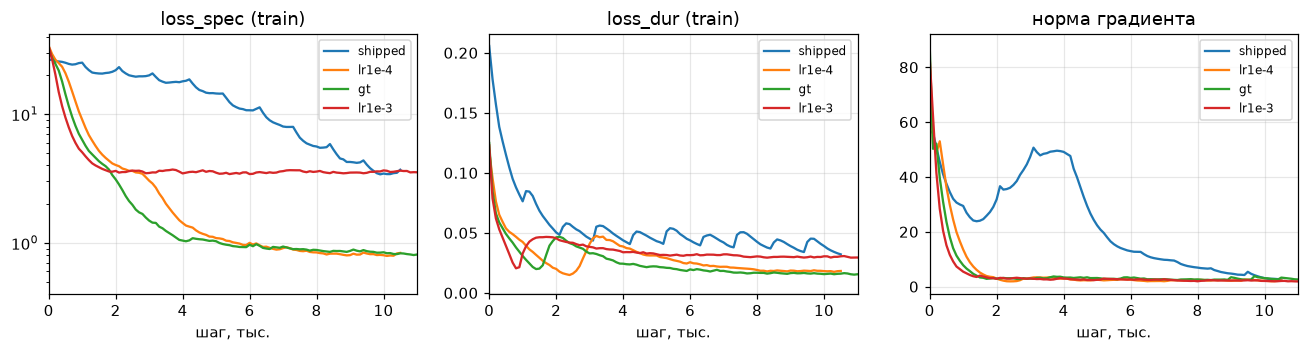

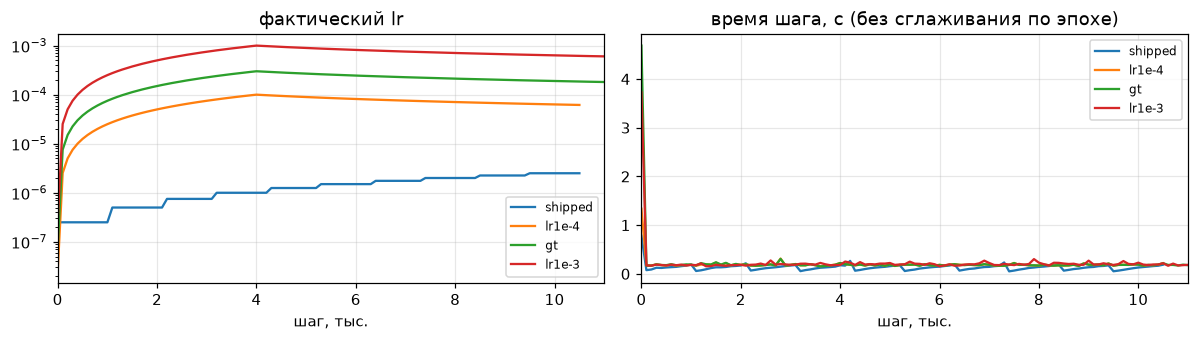

,модель,"MCD модели, дБ",медиана,"MCD пост. мела, дБ","доля фраз, где модель лучше пост. мела",кадры модель/запись,"мел natural [min, max]","мел модели [min, max]",гармоники: рябь модели / записи
0,"shipped (lr 1e-3, раз в эпоху)",61.35,61.30,62.13,75%,0.169,"[-11.39, 0.48]","[-8.11, -2.72]",0.15 / 1.04
1,"lr 1e-4, раз в шаг",29.65,29.02,62.13,100%,0.901,"[-11.39, 0.48]","[-11.18, -0.84]",0.23 / 1.04
2,"lr 3e-4, раз в шаг (gt)",30.45,29.60,62.13,100%,0.902,"[-11.39, 0.48]","[-11.10, -0.92]",0.21 / 1.04
3,"lr 1e-3, раз в шаг",59.62,59.39,62.13,92%,0.791,"[-11.39, 0.48]","[-9.12, -2.88]",0.13 / 1.04


In [24]:
plot_runs(["shipped", "lr1e-4", "gt", "lr1e-3"],
          ["TrainIterStats/loss_spec", "TrainIterStats/loss_dur", "TrainIterStats/grad_norm"],
          ["loss_spec (train)", "loss_dur (train)", "норма градиента"], xmax=11, logy=("TrainIterStats/loss_spec",))
plot_runs(["shipped", "lr1e-4", "gt", "lr1e-3"], ["TrainIterStats/current_lr", "TrainIterStats/step_time"],
          ["фактический lr", "время шага, с (без сглаживания по эпохе)"], xmax=11, logy=("TrainIterStats/current_lr",), alpha=0.0, figsize=(11, 3.2))
display(summary_rows([
    ("shipped (lr 1e-3, раз в эпоху)", "shipped", 10000, False),
    ("lr 1e-4, раз в шаг", "lr1e-4", 10000, False),
    ("lr 3e-4, раз в шаг (gt)", "gt", 10000, False),
    ("lr 1e-3, раз в шаг", "lr1e-3", 10000, False),
]))

**Наблюдения (10 тыс. шагов):**

| запуск | что происходит | MCD | кадры модель/запись | CER |
|---|---|---|---|---|
| `shipped` | lr за 10 эпох вырос лишь до 2,7e-6: `loss_spec` ≈ 7, длительности почти не выучены - модель выдаёт фразу в 6 раз короче записи | 61,4 | 0,17 | 100 % |
| `lr1e-3` | декодер схлопнулся в средний спектр (п. 7 раздела 3), выравниватель и длительности при этом учатся | 59,6 | 0,79 | 95 % |
| `gt` (3e-4) | плато до 2,6 тыс. шагов, затем быстрая сходимость | 30,5 | 0,90 | 5,3 % |
| `lr1e-4` | плато до 3,7 тыс. шагов, затем сходимость | **29,7** | 0,90 | **3,7 %** |

- Выданная схема (`shipped`) за то же время ничему не учится - не из-за значения lr, а из-за расписания, шагающего раз в эпоху: README честно предупреждает о 12–24 часах обучения, и причина именно в этом. Горб нормы градиента около 4 тыс. шагов, по-видимому, - момент, когда растущий lr начинает заметно двигать веса; к 10 тыс. шагов обучение только начинается.
- С пошаговым расписанием всё решает пик lr. 1e-3 слишком велик для post-LN трансформера при батче 16. Между 1e-4 и 3e-4 на 10 тыс. шагов выиграл **1e-4**: train `loss_spec` у него выше, а MCD и CER - лучше; больший шаг даёт более «шумную» модель на том же числе шагов.
- Главное следствие - для выбора 3e-4 было недостаточно коротких пробных запусков: этот шаг оказался **пограничным**. Запуск `g2p` с теми же настройками простоял на плато 26,8 тыс. шагов (раздел 6.1). При повторной постановке эксперимента разумнее брать 1e-4 (или 3e-4 с длительностями MFA, у которых плато нет вовсе, - раздел 7).

## 7. Дополнительное задание 1. Длительности из разметки MFA

`prepare_mfa_durations.py --metadata ../../data/metadata_phones_gt_train.csv --textgrids ../../data/mfa/align_v3 --out ../../data/mfa_durations`. Важно, чтобы фонемы метаданных совпадали с ярусом фонем TextGrid **один-в-один**: GT-метаданные v3 построены из тех же TextGrid v3 - совпадение 100 % (17 475 из 17 475, ни одной фонемы без кадра); для сравнения, с официальной v2 не совпали бы 12 % фраз, с фонемами G2P - 13 %. Флаг `--durations` выключает выравниватель - длительности фиксированы с первого шага.

**Ошибка coqui, найденная на этом запуске.** Первый запуск `mfa_dur` (сохранён как `mfa_dur_bug`) за 31,6 тыс. шагов так и не сошёл с плато `loss_spec ≈ 3,4` - MCD 59,1 дБ при 62,1 у постоянного мела, модель/запись по кадрам 0,64. Сами длительности были в порядке (сумма по каждой фразе точно равна числу кадров мела). Причина - в `TTSDataset.collate_fn` (`TTS/tts/datasets/dataset.py`): батч сначала сортируется по длине текста, а затем матрицы выравнивания **ещё раз** переставляются той же перестановкой (`batch["attn"][idx] for idx in ids_sorted_decreasing` по уже отсортированному списку). При перемешанных батчах каждая фраза получает выравнивание другой фразы батча; несовпадение по длине молча «подрезается» (`dur[largest_idxs] -= 1`), и ошибки не возникает. Проверка на настоящих батчах: у 75 из 80 строк длительности чужие. С внутренним выравнивателем матрицы не используются - остальные запуски ошибка не затрагивает. Исправление - `fix_attention_mask_order()` в `train_fastspeech2.py`: `_sort_batch` возвращает тождественную перестановку, и повторная перестановка ничего не меняет (применяется при импорте модуля, чтобы его получили и воркеры загрузчика, порождаемые через `spawn`); после исправления - 0 из 80. Ниже - повторный запуск `mfa_dur` с исправлением.

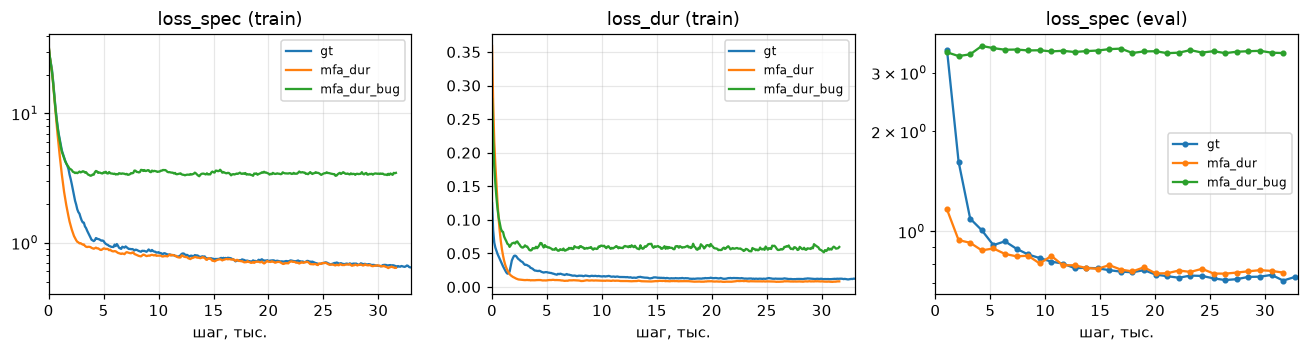

,модель,"MCD модели, дБ",медиана,"MCD пост. мела, дБ","доля фраз, где модель лучше пост. мела",кадры модель/запись,"мел natural [min, max]","мел модели [min, max]",гармоники: рябь модели / записи
0,gt (выравниватель),28.49,27.96,62.13,100%,0.918,"[-11.39, 0.48]","[-11.03, -0.75]",0.24 / 1.04
1,mfa_dur (длительности MFA),28.60,27.86,62.13,100%,0.918,"[-11.39, 0.48]","[-11.05, -0.77]",0.24 / 1.04
2,mfa_dur_bug (до исправления),59.11,59.08,62.13,93%,0.637,"[-11.39, 0.48]","[-9.85, -2.11]",0.14 / 1.04


,модель,класс,фонем,"MFA, мс","модель, мс","MAE, мс",корр.
0,gt,гласная,1218,53.4,71.699997,32.2,0.486
1,gt,согласная,1691,82.5,62.900002,38.2,0.289
2,gt,пауза,118,111.4,78.800003,76.2,0.337
3,mfa_dur,гласная,1218,53.4,51.099998,11.7,0.849
4,mfa_dur,согласная,1691,82.5,78.000000,16.2,0.766
5,mfa_dur,пауза,118,111.4,80.800003,69.2,0.354


In [25]:
plot_runs(["gt", "mfa_dur", "mfa_dur_bug"], ["TrainIterStats/loss_spec", "TrainIterStats/loss_dur", "EvalStats/avg_loss_spec"],
          ["loss_spec (train)", "loss_dur (train)", "loss_spec (eval)"], xmax=33)
display(summary_rows([("gt (выравниватель)", "gt", 30000, False), ("mfa_dur (длительности MFA)", "mfa_dur", 30000, False),
                     ("mfa_dur_bug (до исправления)", "mfa_dur_bug", 30000, False)]))
rows = []
for label, run in [("gt", "gt"), ("mfa_dur", "mfa_dur")]:
    df = eval_at(run, 30000)
    if df is not None:
        rows += duration_report(duration_table(df.attrs["dir"]), label)
display(pd.DataFrame(rows))

**Наблюдения (30 тыс. шагов, сравнение с `gt`):**

- **Плато нет вообще:** `loss_spec` 1,7 уже на 1 тыс. шагов (у `gt` в этот момент 3,5). Значит, плато «среднего спектра» в основных запусках вызвано тем, что в начале обучения выравниватель ещё не сопоставил фонемы с кадрами: декодер получает на одних и тех же кадрах «не те» фонемы, и лучший для L1 ответ - средний спектр. С правильными длительностями с первого шага у декодера сразу есть полезный сигнал. Выравниватель объясняет, как модель *попадает* на плато, но не сколько на нём остаётся: у `g2p` выравнивание сошлось к ~7 тыс. шагов, а декодер вышел с плато лишь на 26,8 тыс. (раздел 6.1) - однажды найденный минимум «среднего» держит и после того, как сигнал появился.
- **Качество:** MCD 28,60 против 28,49 - одинаково; темп тот же (0,918); **CER 2,0 % против 2,9 %** - лучшая разборчивость среди всех моделей на 30 тыс. шагов, на уровне copysynth.
- **Длительности** модель воспроизводит близко к MFA: корреляция 0,85 (гласные) и 0,77 (согласные) против 0,49 / 0,29 у `gt`, MAE 12–16 мс против 32–38. Длительности MFA и проще предсказать: eval `loss_dur` 0,0078 против 0,0115 у выравнивателя - разметка MFA последовательнее. Паузы - так же плохо, как у `gt` (корр. 0,35).
- Шаг на 22 % быстрее (0,144 с против 0,185): выравниватель не считается.
- Запуск до исправления (`mfa_dur_bug`) - пример того, как выглядит обучение на чужих длительностях: MCD 59,1 (почти константа), темп 0,64, CER 90 %.

Вывод: при наличии хорошего внешнего выравнивания (здесь - MFA из лабы 2, совпадающее с фонемами один-в-один) длительности MFA лучше внутреннего выравнивателя: обучение стабильнее, быстрее и даёт более разборчивую речь. Цена - зависимость от внешнего инструмента и строгое требование совпадения фонем.

## 8. Дополнительное задание 2. Предсказатели высоты тона и энергии

`--pitch-energy`: включаются предсказатели F0 и энергии (в coqui - по образцу FastPitch: значения усредняются по фонеме по выравниванию, предсказываются по одному на фонему и через Conv1D-эмбеддинг прибавляются к выходу энкодера). Диапазон F0 - 50–300 Гц (вместо 1–640 Гц по умолчанию, неправильных для мужского голоса). F0 (pYIN) для 17 475 фраз занимает около часа CPU, поэтому кэш посчитан заранее `precompute_pitch_energy.py` (те же классы `F0Dataset`/`EnergyDataset` coqui) параллельно с обучением других моделей.

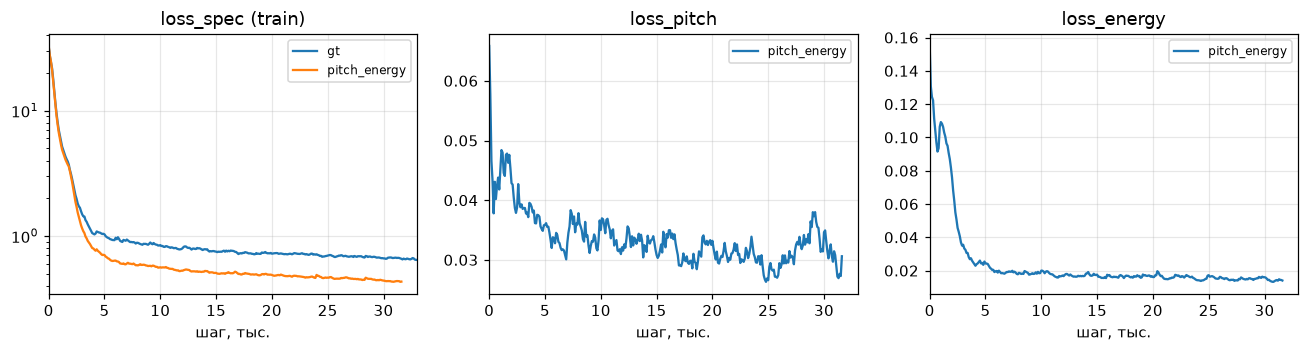

,модель,"MCD модели, дБ",медиана,"MCD пост. мела, дБ","доля фраз, где модель лучше пост. мела",кадры модель/запись,"мел natural [min, max]","мел модели [min, max]",гармоники: рябь модели / записи
0,gt,28.49,27.96,62.13,100%,0.918,"[-11.39, 0.48]","[-11.03, -0.75]",0.24 / 1.04
1,pitch_energy,28.79,28.24,62.13,100%,0.914,"[-11.39, 0.48]","[-11.03, 0.11]",0.83 / 1.04


voiced  фраз с F0  f0_mean  f0_std_st  f0_range_st
run          variant                                                    
gt           model      0.00          8    51.59       0.38         1.04
             natural    0.38        118   123.75       3.14        10.23
pitch_energy model      0.53        120   124.01       1.97         6.13
             natural    0.38        118   123.75       3.14        10.23

,фраз с общими вокализ. кадрами,f0_corr,f0_rmse_st,vuv_acc
run,,,,
gt,3,0.404,15.858,0.623
pitch_energy,117,0.627,2.901,0.718


In [26]:
plot_runs(["gt", "pitch_energy"], ["TrainIterStats/loss_spec", "TrainIterStats/loss_pitch", "TrainIterStats/loss_energy"],
          ["loss_spec (train)", "loss_pitch", "loss_energy"], xmax=33)
display(summary_rows([("gt", "gt", 30000, False), ("pitch_energy", "pitch_energy", 30000, False)]))
f0_rows, agr_rows = [], []
for run in ["gt", "pitch_energy"]:
    df = eval_at(run, 30000)
    if df is None:
        continue
    f0s, agr, _ = f0_table(df.attrs["dir"], run)
    f0_rows.append(f0s); agr_rows.append(agr)
if f0_rows:
    f0s = pd.concat(f0_rows); agr = pd.concat(agr_rows)
    display(f0_agg(f0s[f0s.variant != "copysynth"], ["run", "variant"]))
    a = agr[agr.pair == "model vs natural"]
    t = a.groupby("run")[["f0_corr", "f0_rmse_st", "vuv_acc"]].mean().round(3)
    t.insert(0, "фраз с общими вокализ. кадрами", a.groupby("run").f0_corr.count())
    display(t)

**Наблюдения (30 тыс. шагов, сравнение с `gt`):**

- **Гармоники вернулись:** «рябь» нижних полос 0,83 против 0,24 у `gt` (у записи 1,04); верхняя граница мела −0,11 против −0,75 (у записи +0,48) - пики гармоник снова выше огибающей. Train `loss_spec` 0,44 против 0,67, eval 0,49 против 0,71: зная F0 и энергию, декодер может воспроизвести тонкую структуру, а не усреднять её.
- **Появилась интонация.** pYIN находит тон во всех 120 фразах; средний F0 124 Гц против 124 у записи; контуры коррелируют с записью (0,63 вдоль DTW-пути, расхождение 2,9 полутона). Но интонация **сглажена**: разброс 2,0 полутона против 3,1, размах 6,1 против 10,2 - та же регрессия к среднему, что и у длительностей (F0 предсказывается одним значением на фонему по MSE). Доля вокализованных кадров 53 % против 38 %: модель «озвончает» переходы и часть глухих участков (совпадение тон/не тон - 72 %).
- **MCD чуть хуже** (28,79 против 28,49), хотя eval-лосс намного лучше. Причина - в разнице условий: eval-лосс считается с **настоящими** F0 и энергией записи, а при синтезе используются **предсказанные**. Гармоники на чуть другой высоте MCD штрафует дважды (за лишний пик и за пропущенный), а гладкую огибающую - лишь умеренно. Это ещё один пример того, что MCD поощряет усреднённый спектр.
- Разборчивость: CER 2,1 % против 2,9 % у `gt` на тех же 30 тыс. шагов.
- `loss_pitch` к концу снова немного растёт (≈ 0,030 → 0,032 после 27 тыс. шагов) - первый признак переобучения предсказателя F0.

Вывод: предсказатели высоты тона и энергии устраняют главный недостаток базовой модели - шумоподобный звук без тона - ценой незначительного ухудшения MCD. Для вокодера лабы 5 мел с гармониками существенно ближе к настоящему.

## 9. Итоги

| что | результат |
|---|---|
| обучена модель, которая говорит | `gt`, 80 эпох; CER 2,3 % / WER 7,5 % (copysynth 2,0 / 6,2, запись 1,7 / 5,1) |
| все 120 фраз синтезированы | да (`runs/gt/eval/model/*.wav`) |
| MCD модели ниже постоянного мела | 28,65 против 62,13 дБ |
| диапазон мела сопоставим | да (раздел 5); верхняя граница ниже записи - нет пиков гармоник |
| сравнение GT / G2P | на равном числе шагов после плато - близко, ошибки G2P при синтезе почти не влияют (раздел 6.1) |
| сравнение lr | выданная схема не учится; 1e-3 схлопывается; 1e-4 надёжнее 3e-4 (раздел 6.2) |
| доп. 1: длительности MFA | плато нет, CER 2,0 % на 30 тыс. шагов, длительности ближе к MFA (корр. 0,77–0,85) |
| доп. 2: F0 и энергия | гармоники (рябь 0,83 против 0,24) и тон во всех фразах; интонация сглажена, MCD чуть хуже |

**Главные выводы.**

1. **Большая часть работы - не модель, а обучение.** Выданная конфигурация не дала бы результата за сутки по трём независимым причинам: расписание lr, шагающее раз в эпоху; батч, не помещающийся в 8 ГБ (Windows молча переносит видеопамять в ОЗУ); переподписка потоков BLAS в загрузчике. После исправлений эпоха занимает 3,5 мин, речь появляется через ~3 тыс. шагов.
2. **Плато «среднего спектра» - главный риск FastSpeech 2 с обучаемым выравнивателем.** Выход с него случаен (2,6 тыс. шагов у `gt`, 26,8 тыс. у `g2p` с теми же настройками) и зависит от lr. Попадание на плато вызывает выравниватель (с готовыми длительностями MFA плато нет вовсе), а длительность пребывания на нём от выравнивателя уже не зависит. Практический вывод - брать меньший lr (1e-4) или внешние длительности и сравнивать модели по числу шагов **после** выхода с плато.
3. **MCD - грубая метрика.** Она почти не видит ни гармоник, ни разборчивости (CER продолжает расти после того, как MCD перестаёт меняться), а гармоники на чуть другой высоте штрафует сильнее гладкой огибающей. Поэтому в работе вместе с MCD используются «рябь» нижних полос, F0 (pYIN) и ASR.
4. **Для лабы 5 (вокодер)** лучше подходят мелы модели с предсказателями F0/энергии: в них есть гармоническая структура, без которой нейровокодер будет восстанавливать шумоподобный голос.

Суждения о звучании в разделах 5-8 сделаны по спектрограммам, F0 и распознаванию; оценка на слух - в разделе 10. Аудио для прослушивания - в `runs/<запуск>/eval*/{natural,copysynth,model}/`.

## 10. Оценка на слух

Прослушаны синтезы основной модели (`runs/gt/eval/`) и модели с предсказателями F0 и энергии (`runs/pitch_energy/eval_30k/`) на фразах оценочного набора, в сравнении с записью.

| вариант | впечатление |
|---|---|
| `copysynth` (настоящий мел → Гриффин–Лим) | звучит хорошо, но как будто качество записи снизили до старой телефонной записи (примерно 2–8 кГц) |
| `model`, основная модель `gt` | речь понятная, но очень сильный «робовойс», не похожий на голос диктора; тона и интонации нет. При этом это не шёпот: по громкости голос такой же, как в оригинале |
| `model`, модель `pitch_energy` (доп. задание 2) | голос заметно человечнее за счёт интонации, но «робовойс» всё ещё жёсткий |

**Сопоставление с измерениями.**

- «Телефонное» звучание Гриффина–Лима согласуется со средними спектрами (раздел 5.2): copysynth теряет уровень тем сильнее, чем выше частота. На разборчивость это почти не влияет (CER 2,0 % против 1,7 % у записи).
- Громкость модели совпадает с записью, потому что огибающая спектра (форманты и общий уровень) воспроизведена; не хватает тонкой гармонической структуры, отсюда отсутствие тона при нормальной громкости. Поэтому слово «шумоподобный» в разделах 5.4 и 8 описывает измерения (pYIN не находит в сигнале периодичности), а не восприятие: на слух это не шёпот, а «робовойс».
- Copysynth через тот же Гриффин–Лим «робовойсом» не звучит, значит, причина не в самом вокодере, а в мелах модели: сглаженный по времени и частоте спектр (раздел 5.1) и, у `pitch_energy`, сжатая интонация (разброс F0 2,0 полутона против 3,1 у записи). Вероятно, Гриффин–Лим дополнительно усиливает эффект на таких «гладких» мелах; проверить это можно в лабе 5, подав те же мелы нейровокодеру.